# Seven languages: how fast is the code an AI model writes?

## A summary that runs every morning

A web server writes one line to its access log for every request it answers: when the request arrived, which
page was asked for, whether it worked and how long the server took. A busy site writes a couple of million such
lines a day. Every morning someone wants a short summary: how many requests failed, which pages were the
busiest, and how slow the slowest answers were for each of those pages.

A short program can produce that summary. It reads the file one line at a time, checks that each line has the
expected shape, pulls out the page and the time taken, and keeps running counts. For the 2-million-line log used
in this notebook, a straightforward Python version takes about 5 seconds on a recent laptop.

Five seconds is nothing for a job that runs once a day. It matters when the same work runs thousands of times: on
every file in a data pipeline, behind a dashboard that someone is waiting on, or on a cloud machine billed by the
second. Memory matters in the same way, because whether a job fits in the memory of a small machine decides
whether it runs at all. The language the program is written in changes both.

## Why the same steps can take very different times

Programming languages run code in three broad ways.

Python is interpreted. A program called the interpreter reads your code and carries out each operation as it comes
to it. Before it adds two numbers it checks what kind of values they are, finds the right way to add that kind,
and creates a new object to hold the result. That flexibility makes Python quick to write, and it also means a
loop over two million log lines repeats the bookkeeping two million times.

Rust, C++ and Go are compiled ahead of time. Before the program runs, a compiler translates it into the processor's
own instructions, knowing in advance that a count is a 64-bit integer. The loop that adds up response times
becomes a few machine instructions per line. Rust and C++ leave freeing memory to the program itself; Go adds a
garbage collector, a helper that finds and frees memory the program no longer uses, which costs a little time.

Java, C# and JavaScript take a middle route. The program is first turned into a compact intermediate form. When it
starts, a virtual machine runs that form, notices which parts run most often, and compiles those parts into
machine instructions while the program runs. This is called just-in-time compilation. Long loops can then run
close to compiled speed, but the program pays to start the virtual machine and to warm it up, and all three use a
garbage collector.

Take an illustrative case, adding up a million whole numbers. Python looks up the meaning of `+` for every pair of
values and allocates a new number each time. Rust, C++ and Go keep the running total in a processor register from
the first step. Java, C# and JavaScript start out slower, then compile the loop after it has run a few thousand
times and finish at a similar pace. The useful question is how they compare on realistic work, where reading
files, splitting text and looking things up in tables also take time.

## Python's usual shortcut

Experienced Python programmers rarely write that loop. They use NumPy, a library written in C that stores a million
numbers in one compact block of memory and adds them up in one call, `values.sum()`. The loop still runs, but in
compiled code. A program written this way is still Python, yet for arithmetic on arrays it can run close to
compiled speed.

NumPy only helps when the work can be written as the same operation applied to a whole array at once. Spreading
heat across a floor plan, where every cell of a grid is updated by the same formula at each step, fits well.
Reading a line of JSON or deciding whether a log line is well formed does not: each item needs its own decisions,
and whole-array operations express decisions badly. So Python appears twice here, written with and without NumPy.

## What changes when a model writes the code

The usual argument for Python and for languages with a garbage collector is that they are cheaper to write. C++ and
Rust code is longer, their compilers reject more first drafts, and a developer has to know the language well to
make it fast. Teams often accept slower code because the faster version would cost too much developer time.

AI coding models change part of that calculation. Asking a model for a Rust or C++ version costs about the same as
asking for a Python version. If the model's fast-language code is correct and fast, a team gets the speed without
paying much for it. If the model writes code that is wrong, or no faster than its Python, the gain is not there.
Published language benchmarks, built from programs that experts tuned by hand, cannot answer this. The code that
matters here is the code a model writes when it is asked.

## The question

When an AI coding model writes the same program in Rust, C++, Go, C#, Java, JavaScript and Python (with and without
NumPy), how do the versions compare in run time, memory, length and build time, how much of the gap does NumPy
close, and does each version still give the right answer?

The comparison uses eight tasks written for this study, so no model could have seen them or their answers before.
Two models wrote every version of every task: Claude Sonnet 5.5 and GPT-6.1 Terra, 128 programs in all. A
straightforward Python solution of each task, written for clarity rather than speed, is timed as a ninth version
called "simple Python". It shows what an ordinary Python program would take.

## Study summary

**What was compared.** Each model worked on each task in two agent sessions, one for Rust and both Pythons and one
for C++, Go, C#, Java and JavaScript, with the toolchains, a precise specification and small sample inputs with
their expected outputs. The programs were run on hidden inputs, including one benchmark-sized input per task (2
million log lines, a million JSON transactions, a 300,000-node road network, and so on), and timed five times each,
taking turns, on one laptop.

**Correctness.** All 128 programs and the 8 simple-Python solutions gave the exact expected output on every hidden
input. Correctness sits at its ceiling, so it cannot separate the languages or the models.

**Speed.** For each task and model, a version's relative time is its run time divided by the time of that model's
fastest version on the same task, so 1.0 is the fastest and 2.0 twice as slow. Averaged over the eight tasks
(geometric mean), the order was the same for both models: Rust and C++ first (1.1 for Sonnet's; 1.1 and 2.0 for
Terra's), then Go (1.5 and 1.8), C# (2.1 and 2.1), Java (2.7 and 2.3) and JavaScript (3.3 and 3.3), with NumPy Python
at 8.0 and 6.5 and plain Python at 34 and 25. Rust or C++ was fastest on 15 of the 16 task-and-model pairs; Go won
the other.

**Against Python.** Against the faster of each model's two Python versions, Rust, C++ and Go were 3 to 7 times
faster, C#, Java and JavaScript 2 to 4 times faster. NumPy closed most of the gap on numeric tasks and none of it on
parsing JSON or log lines.

**Memory and start-up.** C++, Rust and Go needed the least memory, about 5 to 7 MB for an empty program and 1.0 to
1.7 times the smallest version on each task; Java needed 5 to 9 times the smallest, as much as Python or more.
Starting an empty program took 0.03 seconds in C++, Rust and Go, 0.07 to 0.12 seconds in JavaScript, C#, Python and
Java, and 0.24 seconds for Python that loads NumPy.

**In the original situation.** The morning log summary took 3.2 to 4.3 seconds in the models' Python versions, 0.4
to 0.8 seconds in Sonnet's six other languages and 1.3 to 3.4 seconds in Terra's. Moving such a job from Python to
the model's fastest language cut its time three to eight times; which model wrote it mattered almost as much as the
language.

**Main caveat.** Each model wrote each program once, on one Windows laptop that was also running other work during
the timing. The order of the language families is consistent across tasks and models; differences of less than
about 30% between two programs, or between two languages of the same family, are not reliable.

## Contents

1. [Setup and saved data](#1-setup-and-saved-data)
2. [The machine](#2-the-machine)
3. [The models](#3-the-models)
4. [The eight tasks](#4-the-eight-tasks)
5. [How the models wrote the programs](#5-how-the-models-wrote-the-programs)
6. [How the programs were checked and timed](#6-how-the-programs-were-checked-and-timed)
7. [Worked example: the heat task in nine versions](#7-worked-example-the-heat-task-in-nine-versions)
8. [Correctness](#8-correctness)
9. [Run time on the full inputs](#9-run-time-on-the-full-inputs)
10. [Which language was fastest](#10-which-language-was-fastest)
11. [Where NumPy helps](#11-where-numpy-helps)
12. [Start-up cost](#12-start-up-cost)
13. [Memory](#13-memory)
14. [Small inputs and start-up time](#14-small-inputs-and-start-up-time)
15. [More cores](#15-more-cores)
16. [Code size and build time](#16-code-size-and-build-time)
17. [The two models, and two larger models on heat](#17-the-two-models-and-two-larger-models-on-heat)
18. [Error analysis: slow choices, not wrong answers](#18-error-analysis-slow-choices-not-wrong-answers)
19. [Measurement quality](#19-measurement-quality)
20. [Limitations](#20-limitations)
21. [What the evidence supports](#21-what-the-evidence-supports)
22. [How the study got here](#22-how-the-study-got-here)
23. [How to reproduce](#23-how-to-reproduce)
24. [Spend](#24-spend)
25. [Future work and further reading](#25-future-work-and-further-reading)

### How the experiment runs

```mermaid
flowchart LR
    spec["8 task specs<br/>+ 3-5 small samples each"] --> s1["16 sessions: Rust, plain Python,<br/>NumPy Python (2 models x 8 tasks)"]
    spec --> s2["16 sessions: C++, Go, C#,<br/>Java, JavaScript"]
    s1 --> progs["128 programs"]
    s2 --> progs
    gen["Input generators<br/>fixed seeds"] --> hidden["Hidden inputs per task<br/>t1 (small) + full (benchmark)"]
    ref["Simple-Python reference<br/>+ independent 2nd implementation"] --> exp["Expected outputs<br/>55 inputs, all agreeing"]
    progs --> build["82 builds<br/>3 clean + 1 incremental each"]
    build --> check["Correctness: 795 runs<br/>samples, t1, full"]
    progs --> check
    hidden --> check
    exp --> check
    check --> time["Timing: 1 warm-up + 5 runs<br/>142 programs on full inputs"]
    time --> out["Run time, memory, start-up,<br/>size sweep, 1-16 workers"]
```

One task travels through this as follows. The heat task's spec and samples go into two fresh folders for each
model. In the first the model writes Rust and both Pythons; in the second, C++, Go, C#, Java and JavaScript. It
builds and tests each version on the samples and stops. The harness copies the source files out, builds every
compiled version with fixed settings, and runs each program on a hidden small input (`t1`) and on the hidden 400 x
400-cell benchmark grid (`full`). Each output is compared with the expected output, computed by the simple-Python
reference and confirmed by a second, independently written implementation. Programs that pass are timed five
times on the benchmark input, taking turns with every other program for the same task, and the median time is the
score. Section 7 follows heat through every step.

The test scripts that ran the sessions and took the measurements live in `bench/`. This notebook only reads their
saved results in `data/`, so running it makes no model calls and no timing runs.

## 1. Setup and saved data

The setup cell loads every saved result table and keeps only rows that match the current programs and inputs: each
row carries the SHA-256 hash of the program and of the input it ran on, and a row whose hashes no longer match is
ignored. It also fixes the nine version names, colours and marker shapes used in every figure: oranges and browns
for Rust, C++ and Go, greens for C#, Java and JavaScript, blues for NumPy and plain Python and grey for simple
Python. Filled markers and solid lines are Claude Sonnet 5.5; open markers and dashed lines are GPT-6.1 Terra.

Two flags at the top, `RUN_SESSIONS` and `RUN_MEASUREMENTS`, are off. Turning them on would rerun the model
sessions (cached by request hash, so nothing is spent while the saved programs match) and the measurements, which
take about two hours and replace the saved timings.

In [1]:
from pathlib import Path
import hashlib, json, subprocess, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from IPython.display import display

RUN_SESSIONS = False
RUN_MEASUREMENTS = False
if RUN_SESSIONS:
    subprocess.run([sys.executable, '-m', 'bench.sessions', 'run-all'], check=True)
if RUN_MEASUREMENTS:
    subprocess.run([sys.executable, '-m', 'bench.measure', 'all'], check=True)
plt.rcParams.update({'font.size': 10, 'axes.titlesize': 12, 'figure.dpi': 150, 'savefig.dpi': 150, 'axes.grid': True, 'grid.alpha': .22})
DATA = Path('data'); RESULTS = DATA / 'results'; FIGURES = Path('figures'); DERIVED = RESULTS / 'derived'
FIGURES.mkdir(exist_ok=True); DERIVED.mkdir(exist_ok=True)
TASKS = ['springs', 'wordpairs', 'ledger', 'logscan', 'routes', 'align', 'heat', 'walkers']
AUTHORS = ['sonnet', 'terra']
# Fixed order, labels, colours and marker shapes for the nine versions. Compiled languages are orange/brown, runtimes with a
# just-in-time compiler or virtual machine are green/teal, Python versions are blue/grey. Marker shape is a second cue.
VERSIONS = ['rust', 'cpp', 'go', 'csharp', 'java', 'js', 'fast', 'plain', 'simple']
MODEL_VERSIONS = VERSIONS[:-1]          # 'simple' is the straightforward reference solution, not model-written
LANGS = ['rust', 'cpp', 'go', 'csharp', 'java', 'js']
LABELS = dict(rust='Rust', cpp='C++', go='Go', csharp='C#', java='Java', js='JavaScript', fast='NumPy Python', plain='Plain Python', simple='Simple Python')
COLORS = dict(rust='#D55E00', cpp='#E69F00', go='#8C510A', csharp='#1B7837', java='#5AB4AC', js='#66A61E', fast='#0072B2', plain='#56B4E9', simple='#777777')
MARKERS = dict(rust='D', cpp='s', go='P', csharp='o', java='v', js='^', fast='X', plain='h', simple='*')
MAIN_FILES = dict(rust='src/main.rs', cpp='main.cpp', java='src/Main.java', csharp='Program.cs', go='main.go', js='main.js')
manifest = json.loads((DATA / 'inputs_manifest.json').read_text(encoding='utf-8'))['inputs']
entries = {(x['task'], x['name']): x for x in manifest}
machine = json.loads((DATA / 'machine.json').read_text(encoding='utf-8'))
SOURCE_SUFFIXES = ('.py', '.rs', '.toml', '.cpp', '.cc', '.h', '.hpp', '.java', '.cs', '.csproj', '.go', '.mod', '.js', '.mjs', '.cjs')
def fingerprint(folder):
    """Hash of the source files of a multi-file program (same recipe as bench/measure.py)."""
    h = hashlib.sha256()
    for p in sorted(folder.rglob('*')):
        if p.is_file() and p.suffix in SOURCE_SUFFIXES and 'target' not in p.parts:
            h.update(p.relative_to(folder).as_posix().encode()); h.update(hashlib.sha256(p.read_bytes()).digest())
    return h.hexdigest()
def source_hash(author, task, variant):
    folder = DATA / 'programs' / author / task
    if variant in MAIN_FILES:
        folder = folder / variant
        if not (folder / MAIN_FILES[variant]).is_file(): return None
        if variant == 'rust' and not (folder / 'Cargo.toml').is_file(): return None
        return fingerprint(folder)
    p = folder / (variant + '.py')
    return hashlib.sha256(p.read_bytes()).hexdigest() if p.is_file() else None
exclusions = []
def current_rows(df, name):
    keep = []
    for _, r in df.iterrows():
        author, task = r['author'], r['task']
        variant = r.get('variant', 'rust')
        expected_source = source_hash(author, task, variant)
        reasons = []
        if expected_source is None: reasons.append('program missing')
        elif 'source_sha256' in df and r['source_sha256'] != expected_source: reasons.append('source hash mismatch')
        elif 'source_sha256' not in df:
            # LOC records have no hash; require a current correctness record for the same source.
            if (author, task, variant, expected_source) not in verified_sources: reasons.append('source not verifiable from correctness')
        if 'input_sha256' in df:
            entry = entries.get((task, r['input']))
            if entry is None or r['input_sha256'] != entry['sha256']: reasons.append('input hash mismatch')
        keep.append(not reasons)
        if reasons: exclusions.append(dict(table=name, author=author, task=task, variant=variant, input=r.get('input', ''), reason=', '.join(reasons)))
    out = df.loc[keep].copy()
    if 'variant' in out: out.loc[out.author.eq('reference') & out.variant.eq('plain'), 'variant'] = 'simple'
    return out
raw_correctness = pd.read_csv(RESULTS / 'correctness.csv')
verified_sources = set()
correctness = current_rows(raw_correctness, 'correctness')
verified_sources = {(r.author, r.task, 'plain' if r.variant == 'simple' else r.variant, r.source_sha256) for r in correctness.itertuples()}
tables = {name: current_rows(pd.read_csv(RESULTS / (name + '.csv')), name) for name in ['builds', 'loc', 'runs', 'sweep', 'scaling']}
baseline = pd.read_csv(RESULTS / 'baseline.csv')
runs, sweep, scaling, builds, loc = (tables[x] for x in ['runs', 'sweep', 'scaling', 'builds', 'loc'])
reference_times = pd.read_csv(DATA / 'reference_times.csv').drop_duplicates(['task', 'name'], keep='last')
def geom(values):
    x = np.asarray(values, dtype=float); x = x[np.isfinite(x) & (x > 0)]
    return np.exp(np.log(x).mean()) if len(x) else np.nan
def savefig(name):
    plt.savefig(FIGURES / name, bbox_inches='tight', dpi=150); plt.show()
def mfc(author, version):
    """Marker face colour: Sonnet filled, Terra open."""
    return 'white' if author == 'terra' else COLORS[version]
def version_handles(versions=VERSIONS, ls='-'):
    return [Line2D([0], [0], marker=MARKERS[v], color=COLORS[v], markeredgecolor='black', markeredgewidth=.4, ms=7, linestyle=ls, label=LABELS[v]) for v in versions]
def author_handles(line=True):
    return [Line2D([0], [0], marker='o', color='black', ls='-' if line else 'none', label='Sonnet: filled marker' + (', solid line' if line else '')),
            Line2D([0], [0], marker='o', color='black', markerfacecolor='white', ls='--' if line else 'none', label='Terra: open marker' + (', dashed line' if line else ''))]

## 2. The machine

All programs ran on one laptop, so its details are part of the result. The processor mixes six performance cores,
each running two threads, with slower efficiency cores. Single-threaded programs were held to the performance cores
so that the operating system could not move them to a slower core between runs. The table lists the processor,
core counts, memory, Windows build, power plan and every toolchain's version.

In [2]:
cores = machine['cpu_sets']; top = max(x['efficiency'] for x in cores)
pcores = len({(x['group'], x['core']) for x in cores if x['efficiency'] == top})
ecores = len({(x['group'], x['core']) for x in cores if x['efficiency'] != top})
def tool_version(key, fallback):
    text = str(machine.get('toolchain_versions', {}).get(key, '')).strip()
    first = text.splitlines()[0] if text else ''
    return first if first and 'flag provided' not in text and 'not recognized' not in text else fallback
display(pd.DataFrame({'value': {'CPU': machine['cpu_name'], 'P-cores': pcores, 'E-cores': ecores,
    'RAM (GB)': round(machine['ram_bytes']/1e9, 2), 'Windows': machine['windows'], 'Windows build': machine['windows_build'],
    'Power plan': machine['active_power_plan'], 'AC power': machine['on_ac_power'], 'Python': machine['python_version'],
    'NumPy': machine['numpy_version'], 'rustc': machine['rustc_version'], 'cargo': machine['cargo_version'],
    'C++ (MSVC)': 'Visual Studio 2022 Community, vcvars64 (compiler version not recorded in machine.json)',
    'Java': tool_version('JAVA', 'not recorded') + ' | ' + tool_version('JAVAC', 'javac not recorded'),
    '.NET SDK (C#)': tool_version('DOTNET', 'not recorded'),
    'Go': tool_version('GO', 'go1.27.3 (from the toolchain folder name; the version flag failed in machine.json)'),
    'Node.js (JavaScript)': tool_version('NODE', 'not recorded'),
    'measured on (UTC)': machine['date_utc']}}))

,value
CPU,Intel(R) Core(TM) Ultra 9 185H
P-cores,6
E-cores,10
RAM (GB),33.74
Windows,Windows-11-10.0.26300-SP0
Windows build,26300
Power plan,Power Scheme GUID: 64a64f24-65b9-4b56-befd-5ec...
AC power,True
Python,"3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:..."
NumPy,2.2.6


## 3. The models

Two models wrote the 128 programs: Claude Sonnet 5.5, run through Anthropic's `claude -p` command, and GPT-6.1
Terra, run through OpenAI's `codex exec`, both at high reasoning effort. Two larger models, Claude Opus 5.5 and
GPT-6.1 Sol, wrote only the heat task in Rust and Python, in the first test of the pipeline, and are a side
comparison in section 17.

The models do not have dated version names, so the pinned version is the model name the command-line tool
accepted, with the tool's version. Claude Code reports the model name in its session log; Codex does not, so only
the requested name is shown for the OpenAI models. No model's size or numeric precision is published.

In [3]:
def usage(x): return json.loads(x) if isinstance(x, str) else (x if isinstance(x, dict) else {})
def load_meta(author, task, kind):
    p = DATA / 'programs' / author / task / ('meta.json' if kind == 'main' else 'meta_langs.json')
    if not p.is_file(): return None
    m = json.loads(p.read_text(encoding='utf-8')); m['kind'] = kind
    return m
meta_rows = []
for a in AUTHORS + ['opus', 'sol']:
    for t in TASKS:
        for kind in ['main', 'langs']:
            if a in ('opus', 'sol') and (t != 'heat' or kind == 'langs'): continue
            m = load_meta(a, t, kind)
            if m: meta_rows.append({k: m.get(k) for k in ['author', 'task', 'kind', 'requested_model', 'reported_model', 'cli_version', 'effort', 'wall_seconds', 'cost_usd', 'turns', 'tool_calls', 'usage']})
sessions = pd.DataFrame(meta_rows)
sessions['cost_usd'] = pd.to_numeric(sessions.cost_usd, errors='coerce')
sessions['input_tokens'] = sessions.usage.map(lambda x: usage(x).get('input_tokens', 0))
sessions['output_tokens'] = sessions.usage.map(lambda x: usage(x).get('output_tokens', 0))
sessions['cache_read_tokens'] = sessions.usage.map(lambda x: usage(x).get('cache_read_input_tokens', usage(x).get('cached_input_tokens', 0)))
sessions['cache_creation_tokens'] = sessions.usage.map(lambda x: usage(x).get('cache_creation_input_tokens', 0))
sessions['group'] = np.where(sessions.author.isin(['opus', 'sol']), 'pilot', sessions.kind)
print('sessions found:', len(sessions), sessions.group.value_counts().to_dict())
why = {'sonnet': "Anthropic's coding model for all 16 sessions (8 main, 8 languages); replaced Opus 5.5 to save subscription quota",
       'terra': "OpenAI's model for the same 16 sessions; replaced Sol for the same reason",
       'opus': 'Larger Anthropic model, heat pilot only', 'sol': 'Larger OpenAI model, heat pilot only'}
model_names = {'sonnet': 'Claude Sonnet 5.5', 'terra': 'GPT-6.1 Terra', 'opus': 'Claude Opus 5.5', 'sol': 'GPT-6.1 Sol'}
prompts = {'sonnet': 'main prompt (AUTHOR_PROMPT.md: Rust, plain and NumPy Python) and languages prompt (AUTHOR_PROMPT_LANGS.md: C++, Java, C#, Go, JavaScript)',
           'terra': 'main prompt (AUTHOR_PROMPT.md: Rust, plain and NumPy Python) and languages prompt (AUTHOR_PROMPT_LANGS.md: C++, Java, C#, Go, JavaScript)',
           'opus': 'main prompt only (heat pilot)', 'sol': 'main prompt only (heat pilot)'}
model_rows = []
for a in ['sonnet', 'terra', 'opus', 'sol']:
    s = sessions[sessions.author.eq(a)]
    claude = a in ['sonnet', 'opus']
    model_rows.append({'model': model_names[a], 'pinned version (requested / reported)': ' / '.join(sorted(set(s.requested_model.dropna()))) + ' / ' + (', '.join(sorted(set(s.reported_model.dropna()))) or 'not reported'),
        'provider and call': 'Anthropic, claude -p' if claude else 'OpenAI, codex exec',
        'CLI version': ', '.join(sorted(set(s.cli_version.dropna()))), 'size and precision': 'not published',
        'settings': ('effort high; tools Bash, Read, Write, Edit, Glob, Grep; ' if claude else 'effort high; workspace-write sandbox tools; ') + 'prompts: ' + prompts[a],
        'why included': why[a]})
display(pd.DataFrame(model_rows))

sessions found: 34 {'main': 16, 'langs': 16, 'pilot': 2}


,model,pinned version (requested / reported),provider and call,CLI version,size and precision,settings,why included
0,Claude Sonnet 5.5,claude-sonnet-5-5 / claude-sonnet-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Gl...",Anthropic's coding model for all 16 sessions (...
1,GPT-6.1 Terra,gpt-6.1-terra / not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace-write sandbox tools; pr...,OpenAI's model for the same 16 sessions; repla...
2,Claude Opus 5.5,claude-opus-5-5 / claude-opus-5-5,"Anthropic, claude -p",2.1.296 (Claude Code),not published,"effort high; tools Bash, Read, Write, Edit, Gl...","Larger Anthropic model, heat pilot only"
3,GPT-6.1 Sol,gpt-6.1-sol / not reported,"OpenAI, codex exec",codex-cli 0.160.1,not published,effort high; workspace-write sandbox tools; pr...,"Larger OpenAI model, heat pilot only"


Other models helped build the study but are not measured: the task specs and this text were written by Claude Opus
5.5; the input generators, the simple-Python reference and the measurement scripts by GPT-6.1 Sol and GPT-6.1
Terra; this notebook's code by GPT-6.1 Terra and Claude Sonnet 5.5.

## 4. The eight tasks

The tasks cover the kinds of work people write scripts for, from pure arithmetic to text and record handling:

- **springs**: 4,000 masses joined by springs in a ring, moved for 15,000 time steps; report the energy. A
  floating-point loop.
- **wordpairs**: count how often each pair of adjacent words occurs in 10 million words of text; report the 20
  most common pairs. Text and hash tables.
- **ledger**: total a million JSON bank transactions per channel and account, with exact currency conversion.
  Parsing records.
- **logscan**: the morning log summary from the introduction, over 2 million lines. Parsing text with a pattern.
- **routes**: shortest road distances from 6 starting points in a 300,000-node network. Graph search.
- **align**: the cheapest weighted edit from one string to another, for 300 pairs. A dynamic-programming table.
- **heat**: heat spreading across a 400 x 400 floor plan for 250 steps, in exact integer arithmetic. Grid
  arithmetic.
- **walkers**: 64 random walks of 500,000 steps each, with a fixed random-number generator, spread over a given
  number of workers. Parallel simulation.

Each task has a written spec with exact input and output formats, in `bench/tasks/<task>/SPEC.md`. The inputs are
generated by code from fixed seeds, so they are new and the expected answers are exact. The first table gives the
benchmark input's size and generator settings, and the median time of the simple-Python solution on it; the second
is how long the reference took when it first generated the expected outputs.

In [4]:
work = {'springs': 'particle simulation', 'wordpairs': 'text pair counting', 'ledger': 'transaction aggregation', 'logscan': 'log parsing and aggregation', 'routes': 'shortest paths', 'align': 'sequence alignment', 'heat': 'grid simulation', 'walkers': 'parallel random walks'}
ref = runs[(runs.author == 'reference') & (runs.input == 'full')].groupby('task').wall_seconds.median()
display(pd.DataFrame([{'task': t, 'work': work[t], 'full input bytes': entries[t, 'full']['bytes'], 'parameters': json.dumps(entries[t, 'full']['parameters']), 'simple Python median (s)': ref.get(t)} for t in TASKS]))
display(reference_times.rename(columns={'wall_seconds': 'reference generation time (s)'}))

,task,work,full input bytes,parameters,simple Python median (s)
0,springs,particle simulation,380975,"{""N"": 4000, ""P"": 4000, ""S"": 15000, ""dt"": 0.0005}",12.868079
1,wordpairs,text pair counting,65546152,"{""vocabulary"": 40000, ""words"": 10000000}",36.393527
2,ledger,transaction aggregation,381005817,"{""accounts"": 10000, ""channels"": 8, ""currencies...",7.306794
3,logscan,log parsing and aggregation,227676727,"{""lines"": 2000000, ""malformed_period"": 100, ""t...",5.041367
4,routes,shortest paths,14809532,"{""M"": 900000, ""N"": 300000, ""Q"": 6}",8.510725
5,align,sequence alignment,270579,"{""P"": 300, ""alphabet"": 10, ""max_length"": 1000,...",10.445237
6,heat,grid simulation,160412,"{""H"": 400, ""S"": 250, ""W"": 400}",14.095855
7,walkers,parallel random walks,35,"{""B"": 300, ""J"": 64, ""L"": 500000, ""SEED"": 18446...",19.097237


,task,name,reference generation time (s)
64,springs,s1a,0.315226
66,wordpairs,full,54.052765
67,ledger,full,11.368453
68,logscan,full,6.788517
69,routes,full,11.134631
70,align,full,20.151020
71,heat,full,20.907135
72,walkers,full,32.018223
73,logscan,s2,0.165326
74,springs,s1b,0.146755


### A look at the data

The input generators add the awkward cases a real file would contain. The log has truncated lines, lower-case
methods and latencies missing their decimal, about 1% of lines in all, which must be counted as malformed. The JSON
transactions contain decoy fields with the same names nested inside other objects, escaped quotes and emoji written
as escape codes, so a program that searches the text for `"account"` instead of parsing the JSON gets the wrong
total. The heat floor plans mark walls with `#`, heat sources with a digit and open floor with `.`. The cell below
prints the first lines of a small sample input and its expected output for these three tasks.

In [5]:
for task in ['logscan', 'ledger', 'heat']:
    print('\n', task)
    for suffix in ['in', 'out']:
        lines = (DATA / 'samples' / task / ('s2.' + suffix)).read_text(encoding='utf-8').splitlines()
        print('s2.' + suffix)
        for line in (lines[:6] if suffix == 'in' else lines): print(line[:140] + ('…' if len(line) > 140 else ''))


 logscan
s2.in
2026-10-30T14:22:05.123Z web-17 GET
2026-10-30T14:22:05.123Z web-17 GET /service/36a/v2/?ref=abc&item=12 200 1834B 9.5ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /service/53a/v2/71170 200 1834B 9.8ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/6929 200 1834B 10.9ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /x//69521/12a 200 1834B 9.6ms "Mozilla/5.0 (X11; Linux x86_64)"
2026-10-30T14:22:05.123Z web-17 GET /api/v2/items/80123?ref=abc&item=12 200 1834B 39.7ms "Mozilla/5.0 (X11; Linux x86_64)"
s2.out
lines 2000
malformed 40
status 1xx 16
status 2xx 1558
status 3xx 153
status 4xx 147
status 5xx 86
path /api/v2/items/{id} 227 13.4 170.0 697.9
path /users/{id}/orders/ 149 12.8 94.2 334.4
path /x//{id}/12a 91 13.9 162.8 250.9
path /{id}/{id}/{id} 62 15.3 73.5 306.1
path /health 61 8.2 82.8 203.7
path /service/0a/v2// 54 22.9 303.9 422.4
path /service/1a/v2/{id} 42 14.5 123.2 1014.3


The first logscan output line counts all 2,000 lines of the sample, the second the malformed ones (the first sample
line is a truncated request). A `path` line such as `path /api/v2/items/{id} 227 13.4 170.0 697.9` says the page
template `/api/v2/items/{id}` (any numeric item id) was requested 227 times, with a median latency of 13.4 ms, a
95th percentile of 170.0 ms and a maximum of 697.9 ms. The ledger line shows a decoy `extra` object holding its own
`account`, `tags` and `type` fields, which a correct program ignores.

## 5. How the models wrote the programs

Each model ran as an agent: a loop in which it reads files, writes code, runs commands such as a build or a test on
a sample, reads the results and decides what to do next, until it judges the work finished. Each model had two
sessions per task, in fresh folders outside the repository and without access to each other: one for Rust and the
two Pythons (`bench/AUTHOR_PROMPT.md`), and one for C++, Go, C#, Java and JavaScript
(`bench/AUTHOR_PROMPT_LANGS.md`).

```mermaid
flowchart TD
    p["Prompt + SPEC.md + samples/<br/>+ starting project per language"] --> m["Model<br/>Sonnet 5.5 via claude -p, or Terra via codex exec<br/>effort high"]
    m -->|"writes code, runs a command"| t["Shell in the task folder<br/>build scripts, test runs on samples"]
    t -->|"output, errors, timings"| m
    m -->|"judges the work done"| out["source files<br/>+ a short summary"]
```

The two prompts share their key instructions:

> Every version must print the correct output for any valid input as SPEC.md defines it, not only for the
> samples. Make each version as fast as you can. Write each one the way a skilled developer in that language
> would write fast code, using that language's own strengths. Use a single thread and a single process unless
> SPEC.md says otherwise.

Every version was limited to its language's standard library, plus the library a developer would usually reach for
where the standard library lacks JSON or regular expressions: serde, serde_json, regex and rayon for Rust,
nlohmann/json 3.12 for C++, Jackson 2.22 for Java, NumPy 2.2 for the NumPy version. They were downloaded in advance
so builds work offline. Compilers and build settings were fixed by the harness: Rust 1.99 in release mode (the
model could change the release profile), Microsoft Visual C++ 19.40 with `/O2 /GL /EHsc /std:c++20`, Go 1.27.3,
.NET 8 in Release mode (the model could change project properties), Java 23 with default JVM settings, Node.js
22.17 and Python 3.13.5.

Asking for the fastest version matters for reading the results. A model's "plain Python" is Python written for
speed, which can be far from Python written in a hurry; the simple-Python reference shows the other end.

The table shows each session's length, tool calls (each command, file read or edit is one call), tokens and cost,
by model, task and session kind (`main` for Rust and Python, `langs` for the other five).

In [6]:
sessions['minutes'] = sessions.wall_seconds / 60
session_cols = ['author', 'task', 'kind', 'minutes', 'tool_calls', 'input_tokens', 'output_tokens', 'cache_read_tokens', 'cache_creation_tokens', 'cost_usd']
display(sessions[session_cols].sort_values(['author', 'kind', 'task']).round(2).reset_index(drop=True))
totals = sessions.groupby(['author', 'kind'])[session_cols[3:]].sum(min_count=1)
totals.insert(0, 'sessions', sessions.groupby(['author', 'kind']).size())
display(totals.round(2))

,author,task,kind,minutes,tool_calls,input_tokens,output_tokens,cache_read_tokens,cache_creation_tokens,cost_usd
0,opus,heat,main,8.03,30,56,29010,769677,47480,1.11
1,sol,heat,main,11.86,30,753520,22568,670720,0,NaN
2,sonnet,align,langs,2.12,15,22,16439,202500,20642,0.27
3,sonnet,heat,langs,3.44,19,28,21053,327297,32810,0.37
4,sonnet,ledger,langs,8.10,33,62,56193,1349311,63013,0.95
5,sonnet,logscan,langs,5.52,26,46,35911,750387,45439,0.62
6,sonnet,routes,langs,3.31,19,32,20020,360217,24643,0.33
7,sonnet,springs,langs,2.55,15,22,19365,227221,24953,0.32
8,sonnet,walkers,langs,2.79,12,18,18054,157253,21140,0.28
9,sonnet,wordpairs,langs,6.43,30,56,38093,697083,44974,0.63


sessions  minutes  tool_calls  input_tokens  output_tokens  \
author kind                                                                
opus   main          1     8.03          30            56          29010   
sol    main          1    11.86          30        753520          22568   
sonnet langs         8    34.25         169           286         225128   
       main          8    80.40         228           440         223229   
terra  langs         8    27.53         117       2596363          58947   
       main          8    24.69          73       2224819          42685   

              cache_read_tokens  cache_creation_tokens  cost_usd  
author kind                                                       
opus   main              769677                  47480      1.11  
sol    main              670720                      0       NaN  
sonnet langs            4071269                 277614      3.77  
       main             7301894                 303466      4.18  
terra  langs            2421248                      0       NaN  
       main             1974272                      0       NaN

Sonnet's 16 sessions took 114.6 minutes in all (USD 7.95) and made 8 to 61 tool calls each; Terra's took 52.3
minutes with 4 to 26 tool calls. Both models tested every version on every sample before finishing, and both wrote
extra tests of their own. Terra iterated less, which shows later in plainer programs.

## 6. How the programs were checked and timed

**Correct answers.** For each task a straightforward reference solution produced the expected output for every
input, and a second solution written a different way had to agree before the input was used; all 55 inputs agreed.
A program's output is compared field by field with the expected output. A failure would be sorted into one of
several kinds: the program did not build, crashed, ran out of time, wrote output that cannot be read in the required
format, or wrote readable output with a wrong value. Only the last kind is a wrong answer. For the spring
simulation, which uses floating-point numbers, values within one part in a billion count as equal.

**Timing.** Every correct program ran once to warm up the disk cache and then five more times on the benchmark
input, taking turns with all the other programs for the same task (up to 17) in a shuffled order. The score is the
median of the five wall-clock times, from starting the program to its exit, as a user would wait for it, including
starting the runtime, reading the input and printing the answer. Single-threaded programs were held to the six
performance cores; their garbage collectors and just-in-time compilers could still use helper threads there.

**Memory.** Peak memory is the largest amount of physical memory the program held at once (Windows calls it the peak
working set), in megabytes of a million bytes.

**Relative time and speed-up.** Relative time compares the versions one model wrote for one task: with a fastest
version at 0.46 s, a version taking 0.92 s has relative time 2.0. A speed-up compares two versions directly: a
Python time of 3.1 s and a Rust time of 0.46 s give 3.1 / 0.46 = 6.8x. Averages over tasks use the geometric mean
(multiply the eight ratios and take the eighth root), because an ordinary average lets one large ratio dominate:
for ratios of 2 and 50, the ordinary average is 26, the geometric mean 10. The 95% intervals come from resampling
the eight tasks with replacement 10,000 times, so they show how much an average depends on which tasks were chosen.

## 7. Worked example: the heat task in nine versions

The heat task describes a floor plan of 400 x 400 cells. Open cells start at 0, heat sources hold a fixed value, and
at each of 250 steps every open cell becomes `(4 * old + up + down + left + right) // 8`, where a neighbour that is
a wall, or lies outside the grid, contributes the cell's own old value. The answer is the sum of the open cells, the
hottest cell and a checksum, in exact integer arithmetic.

Claude Sonnet 5.5 spent 3.5 minutes on Rust and the Pythons and 3.4 minutes on the other five languages. In every
compiled and virtual-machine language it used one plan: add a border of walls so every cell has its neighbours at
fixed distances in memory, and update the grid as one flat array with no branches. The next cell defines two
helpers (`show_code` prints numbered lines of a saved program; `show_run` prints its correctness checks and timing
summary), and the cell after it prints the C++ version's update loop:

In [7]:
SHOW_PATHS = {'rust': 'rust/src/main.rs', 'cpp': 'cpp/main.cpp', 'java': 'java/src/Main.java', 'csharp': 'csharp/Program.cs',
              'go': 'go/main.go', 'js': 'js/main.js', 'plain': 'plain.py', 'fast': 'fast.py', 'simple': 'plain.py'}
def show_code(author, task, variant, start, end):
    author = 'reference' if variant == 'simple' else author
    path = DATA / 'programs' / author / task / SHOW_PATHS[variant]
    for i, line in enumerate(path.read_text(encoding='utf-8').splitlines(), 1):
        if start <= i <= end: print(f'{i:4}  {line}')
def show_run(author, task, variant, input):
    c = correctness[(correctness.author==author)&(correctness.task==task)&(correctness.variant==variant)&(correctness.input==input)]
    c = c[['workers','status','detail','stdout']].copy(); c['stdout'] = c.stdout.fillna('').astype(str).str[:200]; display(c)
    t = pd.concat([runs,sweep,scaling],ignore_index=True)
    t = t[(t.author==author)&(t.task==task)&(t.variant==variant)&(t.input==input)]
    display(t.groupby('workers').wall_seconds.agg(['count','median','min','max']))

In [8]:
show_code('sonnet', 'heat', 'cpp', 9, 14)

   9  static void step(const int* __restrict a, int* __restrict b, const int* __restrict c, const int* __restrict m,
  10                   long long lo, long long hi, long long w2) {
  11      for (long long i = lo; i < hi; i++) {
  12          b[i] = (c[i] * a[i] + ((a[i - 1] + a[i + 1] + a[i - w2] + a[i + w2]) & m[i])) >> 3;
  13      }
  14  }


Here `a` is the grid at the start of the step and `b` the new one, `w2` the padded row width (so `a[i - w2]` is the
cell above), `c[i]` is 4 plus the number of wall or outside neighbours (walls hold 0, so the cell's own value is
counted once for each), and `m[i]` keeps the neighbour sum for open cells and zeroes it for walls and sources.
Because the loop reads memory in order with fixed offsets, the compiler can process several cells per instruction.

The NumPy version does the same arithmetic on whole shifted copies of the grid, one array operation per term:

In [9]:
show_code('sonnet', 'heat', 'fast', 30, 39)

  30      for _ in range(steps):
  31          mul(cur[1:-1, 1:-1], coef, out=tmp)
  32          add(tmp, cur[:-2, 1:-1], out=tmp)
  33          add(tmp, cur[2:, 1:-1], out=tmp)
  34          add(tmp, cur[1:-1, :-2], out=tmp)
  35          add(tmp, cur[1:-1, 2:], out=tmp)
  36          rsh(tmp, 3, out=tmp)
  37          band(tmp, mask, out=tmp)
  38          bor(tmp, fixed, out=nxt[1:-1, 1:-1])
  39          cur, nxt = nxt, cur


The plain-Python version could not use NumPy, and a loop over 160,000 cells for 250 steps takes many seconds (the
simple reference loop takes 14 s). Instead it packs the whole grid into one Python integer, 24 bits per cell, and
moves every cell's neighbours into place with shifts of that one huge number. Python's integers can be any size,
and the interpreter does arithmetic on them in compiled code, so each step is a handful of operations on a number
with about 3.8 million bits:

In [10]:
show_code('sonnet', 'heat', 'plain', 55, 67)

  55  
  56      X = pack(vals)
  57      # keep result: divide by 8 leaves 3 stray bits in the top of each lane
  58      keep = pack(openm) & int.from_bytes(bytes((255, 255, 31)) * n, "little")
  59      F = pack(fixed)
  60      W0, W1, W2, W3 = (pack(a) for a in wall)
  61      # a source cell contributes its own value to wall-adjacent neighbours too,
  62      # which the wall masks handle because X holds the source value.
  63      up_sh = wp * L
  64      for _ in range(steps):
  65          s = (X << 2) + (X << up_sh) + (X >> up_sh) + (X << L) + (X >> L)
  66          s += (X & W0) + (X & W1) + (X & W2) + (X & W3)
  67          X = ((s >> 3) & keep) | F


The next cell shows, for the simple reference and all eight of Sonnet's versions, the correctness check on the
benchmark grid (status and the start of the output) and the five timed runs (count, median, fastest and slowest).

In [11]:
for author, variant in [('reference', 'simple')] + [('sonnet', v) for v in ['cpp', 'rust', 'csharp', 'go', 'java', 'js', 'fast', 'plain']]:
    print(author, variant)
    show_run(author, 'heat', variant, 'full')

reference simple


,workers,status,detail,stdout
108,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,14.095855,13.447706,14.335259


sonnet cpp


,workers,status,detail,stdout
95,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.048559,0.046869,0.051544


... (17 outputs left out)

,count,median,min,max
workers,,,,
1,5,0.428119,0.404144,0.508315


sonnet plain


,workers,status,detail,stdout
93,1,correct,NaN,sum 272113217\nmax 8748 240 346\nchecksum 2148...


,count,median,min,max
workers,,,,
1,5,0.902585,0.826827,0.960396


All nine printed the same `sum`, `max` and `checksum` lines. The medians are 0.049 s for C++, 0.057 s for Rust,
0.106 s for C#, 0.118 s for Go, 0.212 s for Java, 0.236 s for JavaScript, 0.428 s for NumPy, 0.903 s for the
packed-integer plain Python and 14.1 s for the simple loop. Relative to C++, the fastest, that is 1.2 for Rust, 2.2
for C#, 2.4 for Go, 4.3 for Java, 4.8 for JavaScript, 8.7 for NumPy, 18 for plain Python and 290 for simple Python.
On this short task much of each time is start-up: an empty C++ program takes 0.03 s to start and exit on this
machine, an empty Java program 0.12 s (section 12). The packing trick made the standard-library Python 16 times
faster than the simple loop, which shows how far Python written for speed can be from Python written in a hurry.

## 8. Correctness

The first table shows each program's status: `correct` means it printed the expected output on both the hidden
small input and the benchmark input (for walkers, also with every worker count tested). A dash means that version
does not exist for that author. The second table counts statuses per author and version, and the third lists every
failed run with its detail and error output.

In [12]:
required = correctness[correctness.input.isin(['t1', 'full'])].copy()
def program_status(group):
    if set(group.input) != {'t1', 'full'}: return 'missing'
    failed = group[group.status != 'correct']
    if not failed.empty: return failed.status.iloc[0]
    if group.task.iloc[0] == 'walkers':
        if not {1, 4, 16}.issubset(set(group.loc[group.input.eq('t1'), 'workers'])): return 'missing'
        extra = scaling[(scaling.author == group.author.iloc[0]) & (scaling.variant == group.variant.iloc[0])]
        if not {1, 2, 4, 8, 16}.issubset(set(extra.workers)): return 'missing'
        if (extra.status != 'correct').any(): return extra.loc[extra.status != 'correct', 'status'].iloc[0]
    return 'correct'
status = pd.DataFrame([dict(author=a, task=t, variant=v, status=program_status(g))
                       for (a, t, v), g in required.groupby(['author', 'task', 'variant'])])
expected = pd.DataFrame([(a,t,v) for a in AUTHORS for t in TASKS for v in MODEL_VERSIONS] + [('reference',t,'simple') for t in TASKS] + [(a,'heat',v) for a in ['opus','sol'] for v in ['plain','fast','rust']], columns=['author','task','variant'])
status = expected.merge(status, how='left', on=['author','task','variant']).fillna({'status':'missing'})
display(status.pivot(index=['author', 'task'], columns='variant', values='status').reindex(columns=VERSIONS).rename(columns=LABELS).fillna('-'))
counts = status.groupby(['author', 'variant', 'status']).size().unstack(fill_value=0).reindex(columns=['correct', 'wrong', 'unreadable', 'crashed', 'timeout', 'build_failed', 'missing'], fill_value=0)
display(counts.reindex(VERSIONS, level='variant').dropna(how='all'))
failures = required[required.status.ne('correct')][['author', 'task', 'variant', 'input', 'workers', 'status', 'detail', 'stderr']].copy()
failures['stderr'] = failures.stderr.fillna('').astype(str).str[:200]
display(failures)

variant                 Rust      C++       Go       C#     Java JavaScript  \
author    task                                                                
opus      heat       correct        -        -        -        -          -   
reference align            -        -        -        -        -          -   
          heat             -        -        -        -        -          -   
          ledger           -        -        -        -        -          -   
          logscan          -        -        -        -        -          -   
          routes           -        -        -        -        -          -   
          springs          -        -        -        -        -          -   
          walkers          -        -        -        -        -          -   
          wordpairs        -        -        -        -        -          -   
sol       heat       correct        -        -        -        -          -   
sonnet    align      correct  correct  correct  correct  correct    correct   
          heat       correct  correct  correct  correct  correct    correct   
          ledger     correct  correct  correct  correct  correct    correct   
          logscan    correct  correct  correct  correct  correct    correct   
          routes     correct  correct  correct  correct  correct    correct   
          springs    correct  correct  correct  correct  correct    correct   
          walkers    correct  correct  correct  correct  correct    correct   
          wordpairs  correct  correct  correct  correct  correct    correct   
terra     align      correct  correct  correct  correct  correct    correct   
          heat       correct  correct  correct  correct  correct    correct   
          ledger     correct  correct  correct  correct  correct    correct   
          logscan    correct  correct  correct  correct  correct    correct   
          routes     correct  correct  correct  correct  correct    correct   
          springs    correct  correct  correct  correct  correct    correct   
          walkers    correct  correct  correct  correct  correct    correct   
          wordpairs  correct  correct  correct  correct  correct    correct   

variant             NumPy Python Plain Python Simple Python  
author    task                                               
opus      heat           correct      correct             -  
reference align                -            -       correct  
          heat                 -            -       correct  
          ledger               -            -       correct  
          logscan              -            -       correct  
          routes               -            -       correct  
          springs              -            -       correct  
          walkers              -            -       correct  
          wordpairs            -            -       correct  
sol       heat           correct      correct             -  
sonnet    align          correct      correct             -  
          heat           correct      correct             -  
          ledger         correct      correct             -  
          logscan        correct      correct             -  
          routes         correct      correct             -  
          springs        correct      correct             -  
          walkers        correct      correct             -  
          wordpairs      correct      correct             -  
terra     align          correct      correct             -  
          heat           correct      correct             -  
          ledger         correct      correct             -  
          logscan        correct      correct             -  
          routes         correct      correct             -  
          springs        correct      correct             -  
          walkers        correct      correct             -  
          wordpairs      correct      correct             -

status             correct  wrong  unreadable  crashed  timeout  build_failed  \
author    variant                                                               
opus      rust           1      0           0        0        0             0   
          fast           1      0           0        0        0             0   
          plain          1      0           0        0        0             0   
reference simple         8      0           0        0        0             0   
sol       rust           1      0           0        0        0             0   
          fast           1      0           0        0        0             0   
          plain          1      0           0        0        0             0   
sonnet    rust           8      0           0        0        0             0   
          cpp            8      0           0        0        0             0   
          go             8      0           0        0        0             0   
          csharp         8      0           0        0        0             0   
          java           8      0           0        0        0             0   
          js             8      0           0        0        0             0   
          fast           8      0           0        0        0             0   
          plain          8      0           0        0        0             0   
terra     rust           8      0           0        0        0             0   
          cpp            8      0           0        0        0             0   
          go             8      0           0        0        0             0   
          csharp         8      0           0        0        0             0   
          java           8      0           0        0        0             0   
          js             8      0           0        0        0             0   
          fast           8      0           0        0        0             0   
          plain          8      0           0        0        0             0   

status             missing  
author    variant           
opus      rust           0  
          fast           0  
          plain          0  
reference simple         0  
sol       rust           0  
          fast           0  
          plain          0  
sonnet    rust           0  
          cpp            0  
          go             0  
          csharp         0  
          java           0  
          js             0  
          fast           0  
          plain          0  
terra     rust           0  
          cpp            0  
          go             0  
          csharp         0  
          java           0  
          js             0  
          fast           0  
          plain          0

,author,task,variant,input,workers,status,detail,stderr


Every program is correct and the failure list is empty: 128 model-written programs, 8 simple-Python references and
6 heat programs by the two larger models. No program failed to build, crashed, timed out, printed unreadable output
or gave a wrong value.

This is a ceiling. With every program correct, the test cannot rank the models or the languages on correctness, and
128 correct out of 128 still allows a true failure rate of up to about 2.3% for programs like these (95% upper
bound). The specs were exact, every model had samples with expected outputs to test against, and both wrote extra
tests of their own. The rest of the comparison is about speed, memory, code size and build time.

## 9. Run time on the full inputs

The table gives every correct program's median over its five timed runs on the benchmark input, with the fastest
and slowest run. In the figure each row is a task and each marker one version, placed at the geometric mean of the
two models' medians, with a thin line from one model's median to the other's, so a long line marks a version where
the models disagreed. Marker shapes and colours follow the legend. The x-axis is logarithmic: one grid step is a
factor of ten.

In [13]:
ok = status[status.status.eq('correct')][['author', 'task', 'variant']]
full = runs[(runs.input == 'full') & runs.status.eq('correct')].merge(ok, on=['author', 'task', 'variant'])
median = full.groupby(['task', 'author', 'variant']).wall_seconds.agg(['median', 'min', 'max', 'count']).reset_index()
median.to_csv(DERIVED / 'median_times.csv', index=False)
shown = median[median.author.isin(AUTHORS + ['reference'])]
display(shown.pivot_table(index=['task', 'author'], columns='variant', values='median').reindex(columns=VERSIONS).reindex(TASKS, level='task').rename(columns=LABELS).round(4))

variant                Rust     C++      Go      C#    Java  JavaScript  \
task      author                                                          
springs   reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.0980  0.0898  0.1294  0.1718  0.3186      0.2874   
          terra      0.0974  0.1404  0.1538  0.2542  0.2922      0.3797   
wordpairs reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.8707  0.7300  0.9152  1.0503  1.1605      1.2700   
          terra      1.1876  3.5962  1.8621  2.3567  2.5792      2.8084   
ledger    reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.8348  0.6622  0.6534  0.8243  0.9364      1.2039   
          terra      1.2763  9.8274  6.6150  3.5847  2.8943      7.2813   
logscan   reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.4569  0.4215  0.4468  0.5999  0.7796      0.7847   
          terra      1.3480  1.5186  3.3979  2.3004  3.0818      2.5831   
routes    reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.1348  0.2599  0.3768  0.4772  0.5070      0.5544   
          terra      0.5065  0.8050  0.9044  0.9607  1.0602      1.0618   
align     reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.0740  0.0850  0.1097  0.3752  0.2838      0.5333   
          terra      0.1234  0.5340  0.1277  0.3487  0.2749      0.6291   
heat      reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.0566  0.0486  0.1176  0.1063  0.2121      0.2361   
          terra      0.1064  0.0686  0.0922  0.1576  0.2470      0.2357   
walkers   reference     NaN     NaN     NaN     NaN     NaN         NaN   
          sonnet     0.1213  0.0864  0.1064  0.1466  0.2369      0.4454   
          terra      0.3244  0.3127  0.3424  0.4118  0.4462      1.0471   

variant              NumPy Python  Plain Python  Simple Python  
task      author                                                
springs   reference           NaN           NaN        12.8681  
          sonnet           0.4992       12.5120            NaN  
          terra            0.5165       10.9752            NaN  
wordpairs reference           NaN           NaN        36.3935  
          sonnet           2.0719       11.0717            NaN  
          terra            5.5456       12.8010            NaN  
ledger    reference           NaN           NaN         7.3068  
          sonnet           8.4520        6.5939            NaN  
          terra            7.0264        7.2292            NaN  
logscan   reference           NaN           NaN         5.0414  
          sonnet           3.1560        3.3414            NaN  
          terra            4.2740        4.0232            NaN  
routes    reference           NaN           NaN         8.5107  
          sonnet           2.1502        5.6797            NaN  
          terra           10.4310        8.5986            NaN  
align     reference           NaN           NaN        10.4452  
          sonnet           0.5445        6.2342            NaN  
          terra            1.3306        9.3533            NaN  
heat      reference           NaN           NaN        14.0959  
          sonnet           0.4281        0.9026            NaN  
          terra            0.4233        6.5658            NaN  
walkers   reference           NaN           NaN        19.0972  
          sonnet           0.9051       13.9128            NaN  
          terra            1.6088       16.5425            NaN

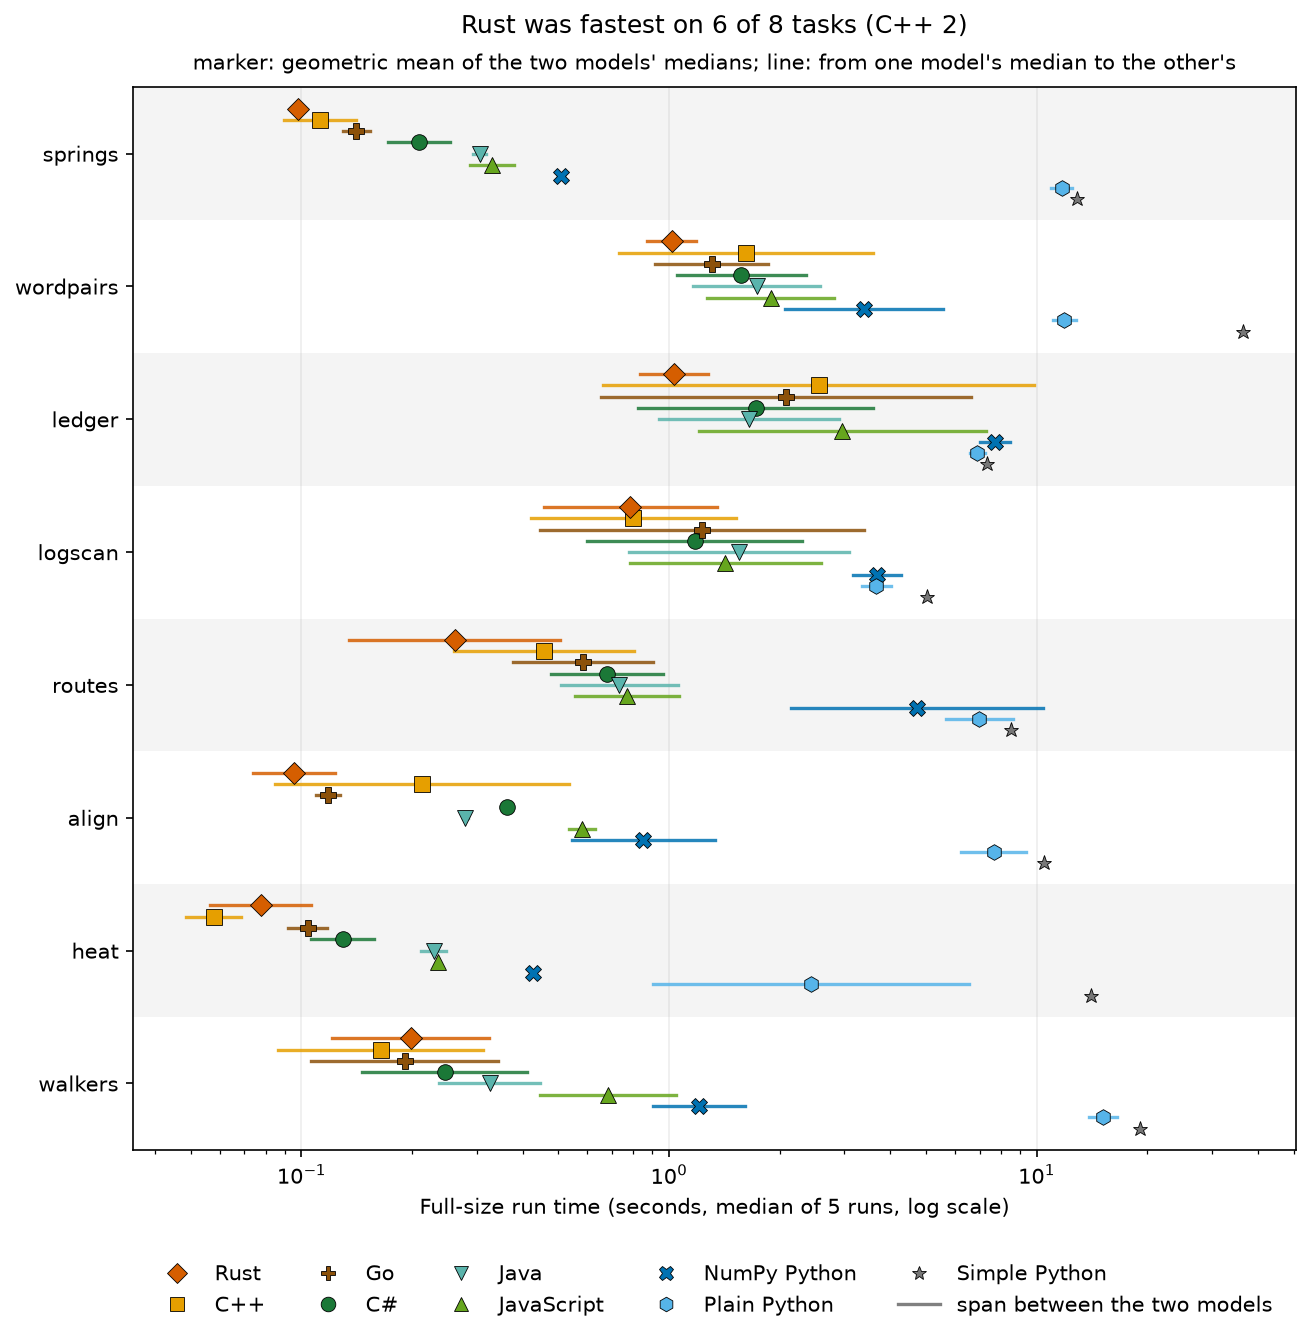

Rust was fastest on 6 of 8 tasks (C++ 2)


In [14]:
OFFS = {v: (i - (len(VERSIONS) - 1) / 2) * .085 for i, v in enumerate(VERSIONS)}
def combine_authors(df, col):
    """Per task and version: geometric mean over the model authors (the reference for Simple Python) and the span between them."""
    rows = []
    for (t, v), g in df.groupby(['task', 'variant']):
        vals = g[col].to_numpy(dtype=float)
        rows.append(dict(task=t, variant=v, gm=geom(vals), lo=vals.min(), hi=vals.max(), n=len(vals)))
    return pd.DataFrame(rows)
def strip_by_task(ax, comb, xlabel):
    for ti in range(0, len(TASKS), 2): ax.axhspan(ti - .5, ti + .5, color='black', alpha=.045, lw=0)
    for r in comb.itertuples():
        y = TASKS.index(r.task) + OFFS[r.variant]
        if r.hi > r.lo: ax.plot([r.lo, r.hi], [y, y], color=COLORS[r.variant], lw=1.6, alpha=.85)
        ax.plot(r.gm, y, marker=MARKERS[r.variant], ms=7.5, color=COLORS[r.variant], markeredgecolor='black', markeredgewidth=.4, ls='none')
    ax.set(xscale='log', yticks=range(len(TASKS)), yticklabels=TASKS, xlabel=xlabel, ylim=(len(TASKS) - .5, -.5)); ax.grid(axis='y', visible=False)
def winners_title(comb, verb):
    best = comb.loc[comb.groupby('task').gm.idxmin()].variant.value_counts()
    top = best.index[0]
    rest = ', '.join(f'{LABELS[v]} {n}' for v, n in best.iloc[1:].items())
    return f'{LABELS[top]} {verb} on {best.iloc[0]} of {len(TASKS)} tasks' + (f' ({rest})' if rest else ''), best
time_comb = combine_authors(median[median.author.isin(AUTHORS + ['reference'])], 'median')
title, best_counts = winners_title(time_comb, 'was fastest')
fig, ax = plt.subplots(figsize=(10, 9.2))
strip_by_task(ax, time_comb, 'Full-size run time (seconds, median of 5 runs, log scale)')
ax.set_title(title, fontsize=12, pad=26)
ax.text(.5, 1.012, 'marker: geometric mean of the two models\' medians; line: from one model\'s median to the other\'s', transform=ax.transAxes, ha='center', va='bottom', fontsize=10)
ax.legend(handles=version_handles(ls='none') + [Line2D([0], [0], color='gray', lw=1.6, label='span between the two models')], loc='upper center', bbox_to_anchor=(.5, -.09), ncol=5, frameon=False)
savefig('runtime_by_task.png')
print(title)

The rows show three groups. Rust, C++ and Go sit at the left, between 0.05 and 1.5 s on most tasks. C#, Java and
JavaScript sit just to their right, typically 1.5 to 3 times slower. The Python versions sit far to the right: NumPy
at 0.4 to 10 s, plain Python at 1 to 17 s and simple Python at 5 to 36 s. Heat shows the effect of a good plain
Python program: Sonnet's packed integer (0.9 s) sits far from Terra's cell loop (6.6 s). The long lines on ledger,
logscan and wordpairs are the models disagreeing about how to parse text, which section 18 explains.

## 10. Which language was fastest

For each task and model, a version's relative time is its median divided by the fastest median among that model's
versions on the task. The table gives the geometric mean over the eight tasks with its 95% bootstrap interval, and
the figure draws it: one row per version, a filled marker for Sonnet and an open one for Terra, bars for the
interval, a log x-axis and a dashed line at 1 (the fastest version). The second table gives the speed-up of each
compiled or virtual-machine language over the faster of the same model's two Python versions.

author,sonnet,terra
version,,
Rust,1.14,1.06
C++,1.11,2.00
Go,1.49,1.75
C#,2.06,2.12
Java,2.67,2.31
JavaScript,3.30,3.25
NumPy Python,7.99,6.46
Plain Python,34.03,24.59
Simple Python,69.54,33.40


,author,version,geometric_mean,ci_low,ci_high
0,sonnet,Rust,1.14,1.06,1.24
1,terra,Rust,1.06,1.00,1.18
2,sonnet,C++,1.11,1.00,1.30
3,terra,C++,2.00,1.26,3.38
4,sonnet,Go,1.49,1.19,1.91
5,terra,Go,1.75,1.30,2.52
6,sonnet,C#,2.06,1.55,2.91
7,terra,C#,2.12,1.77,2.50
8,sonnet,Java,2.67,1.99,3.49
9,terra,Java,2.31,1.95,2.76


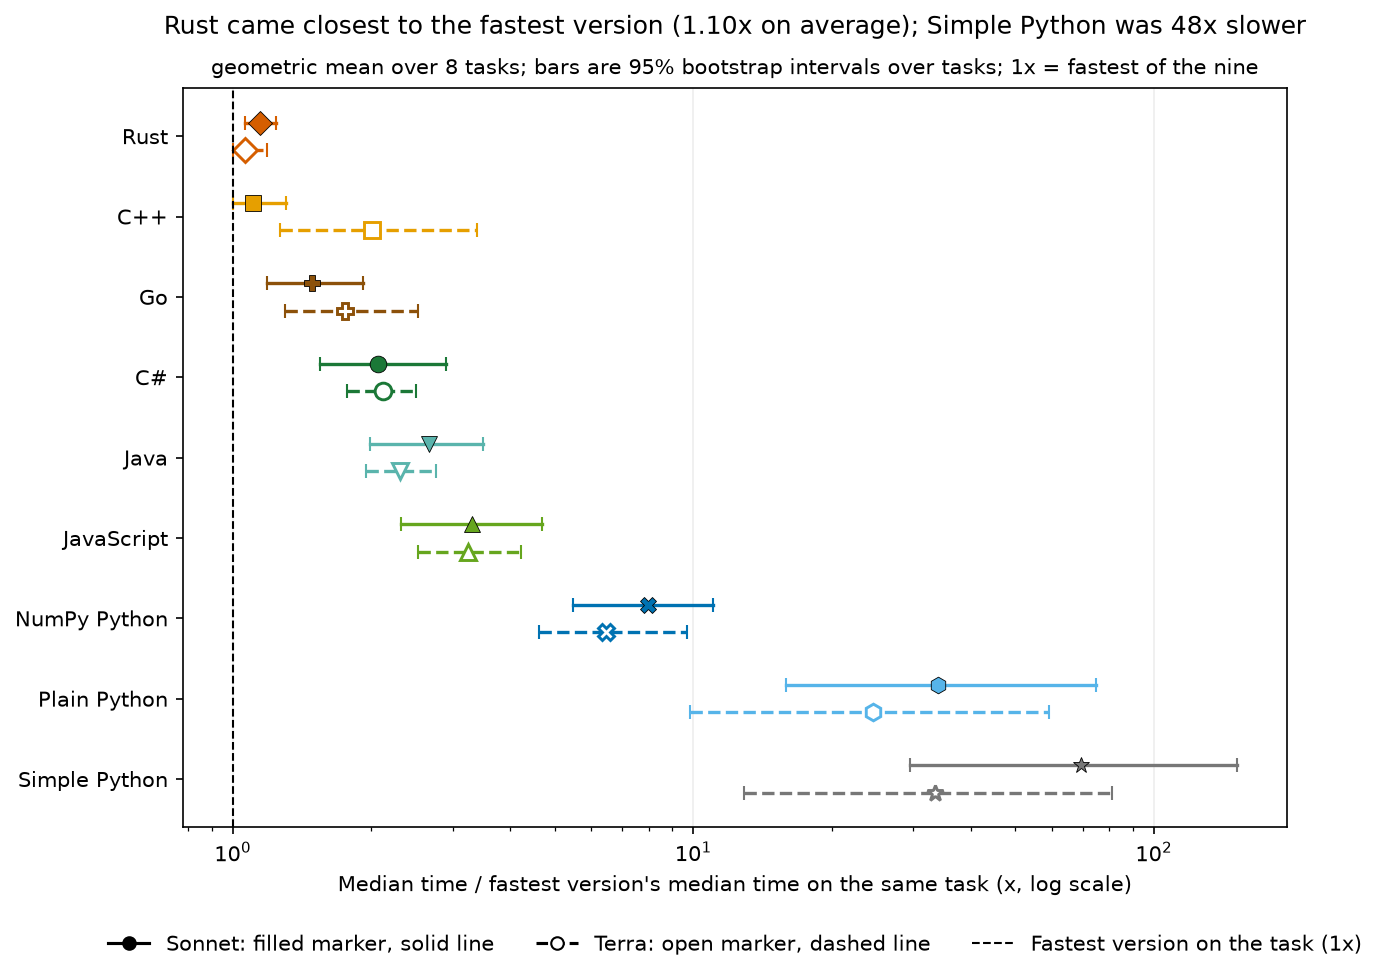

geometric_mean       ci_low       ci_high      
author             sonnet terra sonnet terra  sonnet terra
language                                                  
Rust                 6.77  5.90   4.68  4.24    9.36  8.67
C++                  7.00  3.12   5.16  1.79    8.85  5.30
Go                   5.21  3.58   3.76  2.05    7.13  6.10
C#                   3.75  2.96   2.54  2.17    5.36  4.32
Java                 2.90  2.71   2.05  1.87    4.15  4.13
JavaScript           2.34  1.93   1.65  1.38    3.41  3.04

author                            sonnet  terra
language   baseline                            
Rust       Simple Python           60.75  31.47
           Plain Python            29.73  23.17
           NumPy Python             6.98   6.09
           Faster Python version    6.77   5.90
C++        Simple Python           62.85  16.66
           Plain Python            30.76  12.27
           NumPy Python             7.22   3.22
           Faster Python version    7.00   3.12
Go         Simple Python           46.82  19.08
           Plain Python            22.91  14.05
           NumPy Python             5.38   3.69
           Faster Python version    5.21   3.58
C#         Simple Python           33.69  15.78
           Plain Python            16.49  11.62
           NumPy Python             3.87   3.05
           Faster Python version    3.75   2.96
Java       Simple Python           26.04  14.46
           Plain Python            12.74  10.65
           NumPy Python             2.99   2.80
           Faster Python version    2.90   2.71
JavaScript Simple Python           21.05  10.28
           Plain Python            10.30   7.57
           NumPy Python             2.42   1.99
           Faster Python version    2.34   1.93

In [15]:
mt = median.set_index(['task', 'author', 'variant'])['median']
def med(task, author, version):
    x = mt.get((task, 'reference' if version == 'simple' else author, version))
    return float(x) if x is not None and np.isfinite(x) else None
# Relative speed: each version's median divided by the fastest median among the nine versions on that task (1.0 = fastest).
rel_rows = []
for a in AUTHORS:
    for t in TASKS:
        vals = {v: med(t, a, v) for v in VERSIONS}; vals = {v: x for v, x in vals.items() if x is not None}
        best = min(vals.values())
        for v, x in vals.items(): rel_rows.append(dict(task=t, author=a, version=v, ratio=x / best))
rel_pairs = pd.DataFrame(rel_rows)
rng = np.random.default_rng(39)
def bootstrap_geom(x, n=10000):
    x = np.asarray(x, dtype=float); boot = np.exp(np.log(rng.choice(x, size=(n, len(x)), replace=True)).mean(axis=1))
    return geom(x), np.quantile(boot, .025), np.quantile(boot, .975)
rel = pd.DataFrame([dict(author=a, version=v, geometric_mean=g, ci_low=lo, ci_high=hi, tasks=len(x))
                    for (a, v), x in ((k, d.ratio.to_numpy()) for k, d in rel_pairs.groupby(['author', 'version']))
                    for g, lo, hi in [bootstrap_geom(x)]])
rel['order'] = rel.version.map(VERSIONS.index); rel = rel.sort_values(['order', 'author']).drop(columns='order').reset_index(drop=True)
rel[['author', 'version', 'geometric_mean', 'ci_low', 'ci_high']].to_csv(DERIVED / 'relative_speed.csv', index=False)
rel_pairs[['task', 'author', 'version', 'ratio']].to_csv(DERIVED / 'relative_speed_pairs.csv', index=False)
display(rel.pivot(index='version', columns='author', values='geometric_mean').reindex(VERSIONS).rename(index=LABELS).round(2))
display(rel.assign(version=rel.version.map(LABELS)).drop(columns='tasks').round(2))
overall = rel_pairs.groupby('version').ratio.apply(geom)
best_v, worst_v = overall.idxmin(), overall.idxmax()
fig, ax = plt.subplots(figsize=(9.5, 6.4))
for i, v in enumerate(VERSIONS):
    for a, dy in [('sonnet', -.17), ('terra', .17)]:
        r = rel[(rel.author == a) & (rel.version == v)].iloc[0]
        ax.plot([r.ci_low, r.ci_high], [i + dy] * 2, color=COLORS[v], lw=1.6, ls='--' if a == 'terra' else '-')
        ax.plot([r.ci_low, r.ci_high], [i + dy] * 2, color=COLORS[v], marker='|', ms=7, ls='none')
        ax.plot(r.geometric_mean, i + dy, marker=MARKERS[v], ms=8, color=COLORS[v], markerfacecolor=mfc(a, v), markeredgecolor=COLORS[v] if a == 'terra' else 'black', markeredgewidth=1.4 if a == 'terra' else .4, ls='none')
ax.axvline(1, color='black', ls='--', lw=1)
ax.set(xscale='log', yticks=range(len(VERSIONS)), yticklabels=[LABELS[v] for v in VERSIONS], ylim=(len(VERSIONS) - .4, -.6),
       xlabel='Median time / fastest version\'s median time on the same task (x, log scale)')
ax.grid(axis='y', visible=False)
ax.set_title(f'{LABELS[best_v]} came closest to the fastest version ({overall[best_v]:.2f}x on average); {LABELS[worst_v]} was {overall[worst_v]:.0f}x slower', fontsize=12, pad=26)
ax.text(.5, 1.012, 'geometric mean over 8 tasks; bars are 95% bootstrap intervals over tasks; 1x = fastest of the nine', transform=ax.transAxes, ha='center', va='bottom', fontsize=10)
ax.legend(handles=author_handles(line=True) + [Line2D([0], [0], color='black', ls='--', lw=1, label='Fastest version on the task (1x)')], loc='upper center', bbox_to_anchor=(.5, -.12), ncol=3, frameon=False)
savefig('relative_speed.png')
# Speed-up of each compiled or JIT language over the Python versions, per model.
speed_rows = []
for a in AUTHORS:
    for t in TASKS:
        base = {'simple': med(t, a, 'simple'), 'plain': med(t, a, 'plain'), 'fast': med(t, a, 'fast')}
        base['faster'] = min(base['plain'], base['fast'])
        for lang in LANGS:
            x = med(t, a, lang)
            if x is None: continue
            for b, y in base.items(): speed_rows.append(dict(task=t, author=a, language=lang, baseline=b, speedup=y / x))
speed = pd.DataFrame(speed_rows)
SPEED_LABELS = dict(simple='Simple Python', plain='Plain Python', fast='NumPy Python', faster='Faster Python version')
sp_rows = []
for (a, lang, b), d in speed.groupby(['author', 'language', 'baseline']):
    g, lo, hi = bootstrap_geom(d.speedup)
    sp_rows.append(dict(author=a, language=LABELS[lang], baseline=SPEED_LABELS[b], geometric_mean=g, ci_low=lo, ci_high=hi))
speedups = pd.DataFrame(sp_rows)
speedups['o'] = speedups.language.map({LABELS[l]: i for i, l in enumerate(LANGS)}); speedups['bo'] = speedups.baseline.map({v: i for i, v in enumerate(SPEED_LABELS.values())})
speedups = speedups.sort_values(['author', 'o', 'bo']).drop(columns=['o', 'bo']).reset_index(drop=True)
speedups.to_csv(DERIVED / 'speedups.csv', index=False)
speed.assign(language=speed.language.map(LABELS), baseline=speed.baseline.map(SPEED_LABELS))[['task', 'author', 'language', 'baseline', 'speedup']].rename(columns={'speedup': 'ratio'}).to_csv(DERIVED / 'speedup_pairs.csv', index=False)
faster_tbl = speedups[speedups.baseline.eq('Faster Python version')].pivot(index='language', columns='author', values=['geometric_mean', 'ci_low', 'ci_high']).reindex([LABELS[l] for l in LANGS])
display(faster_tbl.round(2))
display(speedups.pivot_table(index=['language', 'baseline'], columns='author', values='geometric_mean', sort=False).round(2))

| Version | Sonnet | Terra |
|---|---|---|
| Rust | 1.14 (1.06 to 1.24) | 1.06 (1.00 to 1.18) |
| C++ | 1.11 (1.00 to 1.30) | 2.00 (1.26 to 3.38) |
| Go | 1.49 (1.19 to 1.91) | 1.75 (1.30 to 2.52) |
| C# | 2.06 (1.55 to 2.91) | 2.12 (1.77 to 2.50) |
| Java | 2.67 (1.99 to 3.49) | 2.31 (1.95 to 2.76) |
| JavaScript | 3.30 (2.32 to 4.70) | 3.25 (2.52 to 4.22) |
| NumPy Python | 7.99 (5.49 to 11.0) | 6.46 (4.62 to 9.70) |
| Plain Python | 34.0 (15.9 to 74.9) | 24.6 (9.85 to 59.1) |

The families separate cleanly for both models: the ahead-of-time compiled languages near 1, the virtual-machine
languages around 2 to 3, NumPy Python around 6 to 8 and plain Python above 20. Inside a family the order depends on
the model. Sonnet's C++ and Rust were level (C++ fastest on five tasks, Rust on two, Go on ledger). Terra's Rust was
fastest on six tasks while its C++ averaged twice its Rust's time, mostly because of three tasks discussed in
section 18. Java and C# swapped places between the models; JavaScript was last of the six for both.

Against the faster Python version, Sonnet's Rust, C++ and Go were 6.8, 7.0 and 5.2 times faster and Terra's 5.9,
3.1 and 3.6 times; C#, Java and JavaScript were 3.8, 2.9 and 2.3 times faster for Sonnet and 3.0, 2.7 and 1.9
times for Terra. That is the comparison a team would make when deciding whether to move a Python job: given the
better of the model's two Python versions, how much does each language add.

## 11. Where NumPy helps

The table divides each model's plain-Python time by its NumPy time for every task. A value above 1 means the NumPy
version was faster than the same model's plain version; below 1 means it was slower.

In [16]:
p = median[median.author.isin(AUTHORS)].pivot(index=['task', 'author'], columns='variant', values='median')
display((p['plain'] / p['fast']).rename('plain / NumPy time').unstack().reindex(TASKS).round(3))

author,sonnet,terra
task,,
springs,25.062,21.250
wordpairs,5.344,2.308
ledger,0.780,1.029
logscan,1.059,0.941
routes,2.641,0.824
align,11.449,7.030
heat,2.108,15.511
walkers,15.371,10.283


NumPy paid off when the work is arithmetic over many numbers at once: springs, walkers and align, where it made
Python roughly 7 to 25 times faster, and heat against Terra's ordinary cell loop. It did nothing for the parsing
tasks. Each JSON line or log line still has to be read by Python code one item at a time, and NumPy can only take
over after that: on logscan the two versions were level, and on ledger Sonnet's NumPy version was slower than its
plain one (8.5 s against 6.6 s) and Terra's no faster (7.0 s against 7.2 s). Routes shows the effect of how NumPy is used: Sonnet's NumPy version was 2.6 times faster than its
plain one, Terra's slower (section 18).

## 12. Start-up cost

Every runtime pays a fixed cost before it does any work. The next cell runs a program that prints one word and
exits, 20 times in each runtime, and draws the median start-up time and peak memory as bars.

,startup_s,working_set_MB,repeats
version,,,
Rust,0.0319,5.1692,20
C++,0.0299,4.6612,20
Go,0.0322,6.6806,20
C#,0.0791,23.7711,20
Java,0.1157,43.7494,20
JavaScript,0.0725,28.7744,20
NumPy Python,0.2409,27.2466,20
Plain Python,0.1062,14.5183,20


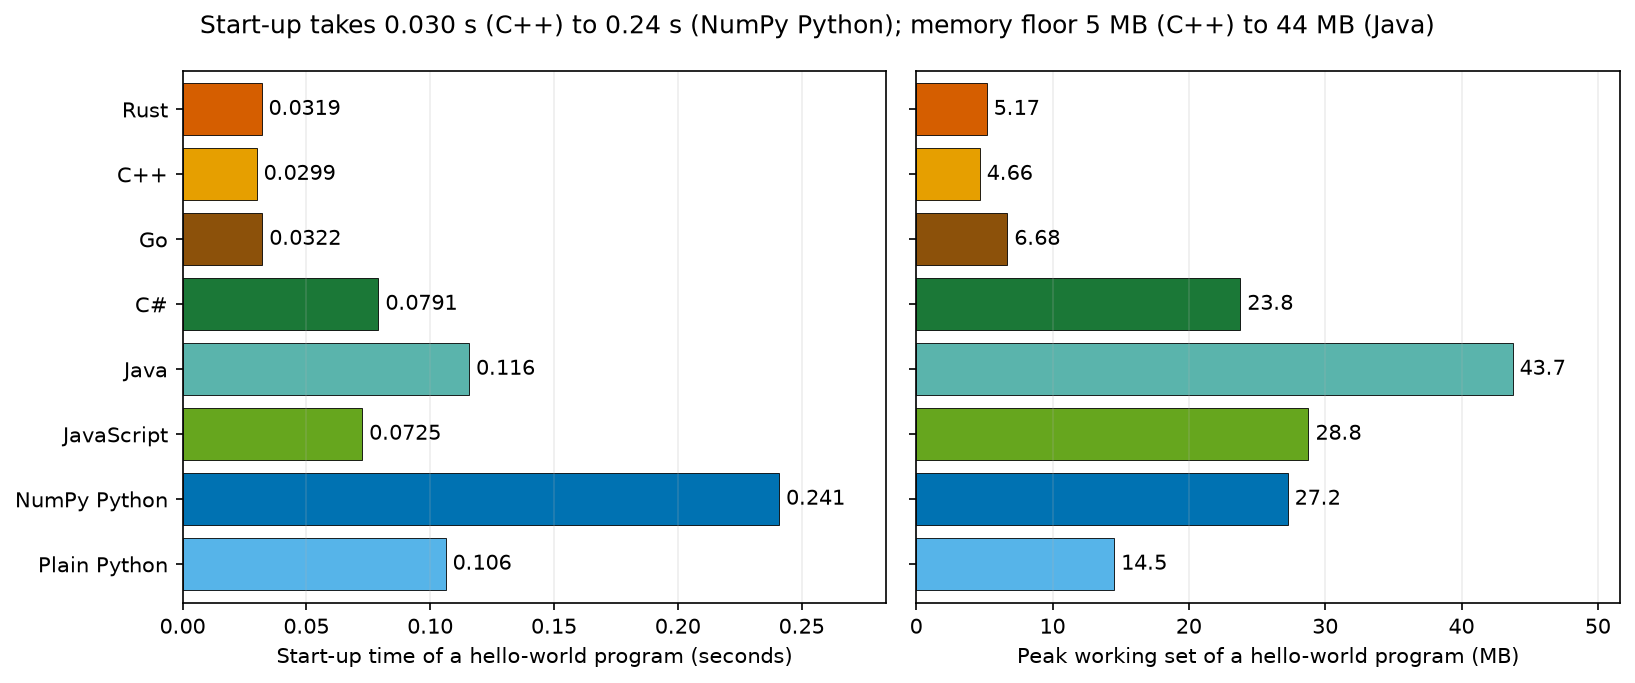

In [17]:
# Hello-world programs in every runtime: the cost of starting the runtime before any task work happens.
BASE_VERSION = dict(python='plain', numpy='fast', rust='rust', cpp='cpp', go='go', csharp='csharp', java='java', js='js')
bl = baseline.copy(); bl['version'] = bl.variant.map(BASE_VERSION)
floor = bl.groupby('version').agg(startup_s=('wall_seconds', 'median'), working_set_MB=('peak_working_set', lambda x: x.median() / 1e6), repeats=('wall_seconds', 'size')).reindex([v for v in VERSIONS if v != 'simple'])
display(floor.rename(index=LABELS).round(4))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, col, xl in zip(axes, ['startup_s', 'working_set_MB'], ['Start-up time of a hello-world program (seconds)', 'Peak working set of a hello-world program (MB)']):
    ys = range(len(floor)); ax.barh(list(ys), floor[col], color=[COLORS[v] for v in floor.index], edgecolor='black', linewidth=.4)
    for y, (v, x) in zip(ys, floor[col].items()): ax.text(x, y, f' {x:.3g}', va='center', fontsize=10)
    ax.set(yticks=list(ys), yticklabels=[LABELS[v] for v in floor.index], xlabel=xl, ylim=(len(floor) - .4, -.6), xlim=(0, floor[col].max() * 1.18)); ax.grid(axis='y', visible=False)
axes[1].set_yticklabels([])
slow_s, fast_s = floor.startup_s.idxmax(), floor.startup_s.idxmin(); big_m, small_m = floor.working_set_MB.idxmax(), floor.working_set_MB.idxmin()
fig.suptitle(f'Start-up takes {floor.startup_s.min():.3f} s ({LABELS[fast_s]}) to {floor.startup_s.max():.2f} s ({LABELS[slow_s]}); memory floor {floor.working_set_MB.min():.0f} MB ({LABELS[small_m]}) to {floor.working_set_MB.max():.0f} MB ({LABELS[big_m]})', fontsize=12)
fig.tight_layout(); savefig('startup_floor.png')

An empty program took 0.030 s and 4.7 MB in C++, 0.032 s and 5.2 MB in Rust, 0.032 s and 6.7 MB in Go, 0.073 s and
28.8 MB in Node.js, 0.079 s and 23.8 MB in .NET, 0.106 s and 14.5 MB in Python, 0.116 s and 43.7 MB in Java, and
0.241 s and 27.2 MB in Python that imports NumPy. Windows starts processes more slowly than Linux, so all of these
are higher than they would be on a Linux server, but their order would be the same. These floors explain much of
the small-input results in section 14 and part of every short task's time.

## 13. Memory

The figure has the same layout as the run-time figure, with peak memory in megabytes on a logarithmic x-axis. The
table after it gives each version's geometric-mean memory relative to the smallest version on each task.

variant               Rust    C++     Go     C#   Java  JavaScript  \
task      author                                                     
springs   reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet       5.4    4.9    8.4   30.1   56.1        39.3   
          terra        5.4    5.2    8.3   28.7   54.3        39.1   
wordpairs reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet     520.0  206.8  211.0  292.6  384.4       236.8   
          terra      287.9  275.0  349.8  360.7  406.2       302.5   
ledger    reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet      10.3    9.7   13.9   32.2   68.3        42.9   
          terra        7.9    5.9   16.8   50.9  381.4       125.0   
logscan   reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet     253.9   42.1  104.0   78.7  110.7        72.7   
          terra       27.9   79.7  130.8  143.1  619.4       157.6   
routes    reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet      45.9   54.9   46.4   63.7  114.1        66.2   
          terra       74.9   31.9   35.0   52.7   74.6        79.1   
align     reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet       5.4    4.7    7.2   25.6   50.5        33.9   
          terra        5.3    5.2    7.2   25.5   48.2        36.4   
heat      reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet       8.1    7.3   11.4   28.8   51.7        36.3   
          terra       16.2    7.6   10.1   27.6   51.0        36.9   
walkers   reference    NaN    NaN    NaN    NaN    NaN         NaN   
          sonnet       5.2    4.8    7.2   24.8   49.2        35.5   
          terra        5.3    4.8    7.2   25.0   48.8        50.9   

variant              NumPy Python  Plain Python  Simple Python  
task      author                                                
springs   reference           NaN           NaN           21.5  
          sonnet             30.7          19.3            NaN  
          terra              30.8          18.1            NaN  
wordpairs reference           NaN           NaN         1921.8  
          sonnet            560.6         865.8            NaN  
          terra             422.9         768.0            NaN  
ledger    reference           NaN           NaN           20.6  
          sonnet            100.8          86.9            NaN  
          terra              16.6          16.4            NaN  
logscan   reference           NaN           NaN           63.4  
          sonnet             94.7          59.1            NaN  
          terra              53.5          58.0            NaN  
routes    reference           NaN           NaN          288.2  
          sonnet            250.3         281.1            NaN  
          terra             284.6         273.5            NaN  
align     reference           NaN           NaN           18.0  
          sonnet             28.4          16.5            NaN  
          terra              28.7          16.3            NaN  
heat      reference           NaN           NaN           40.3  
          sonnet             37.9          25.9            NaN  
          terra              34.4          58.5            NaN  
walkers   reference           NaN           NaN           17.5  
          sonnet             46.8          16.9            NaN  
          terra              29.2          17.0            NaN

author,sonnet,terra
geometric-mean memory / smallest,,
Rust,1.49,1.30
C++,1.02,1.14
Go,1.48,1.73
C#,3.10,3.85
Java,5.45,8.67
JavaScript,3.58,5.52
NumPy Python,5.35,4.00
Plain Python,3.93,3.76
Simple Python,3.99,4.38


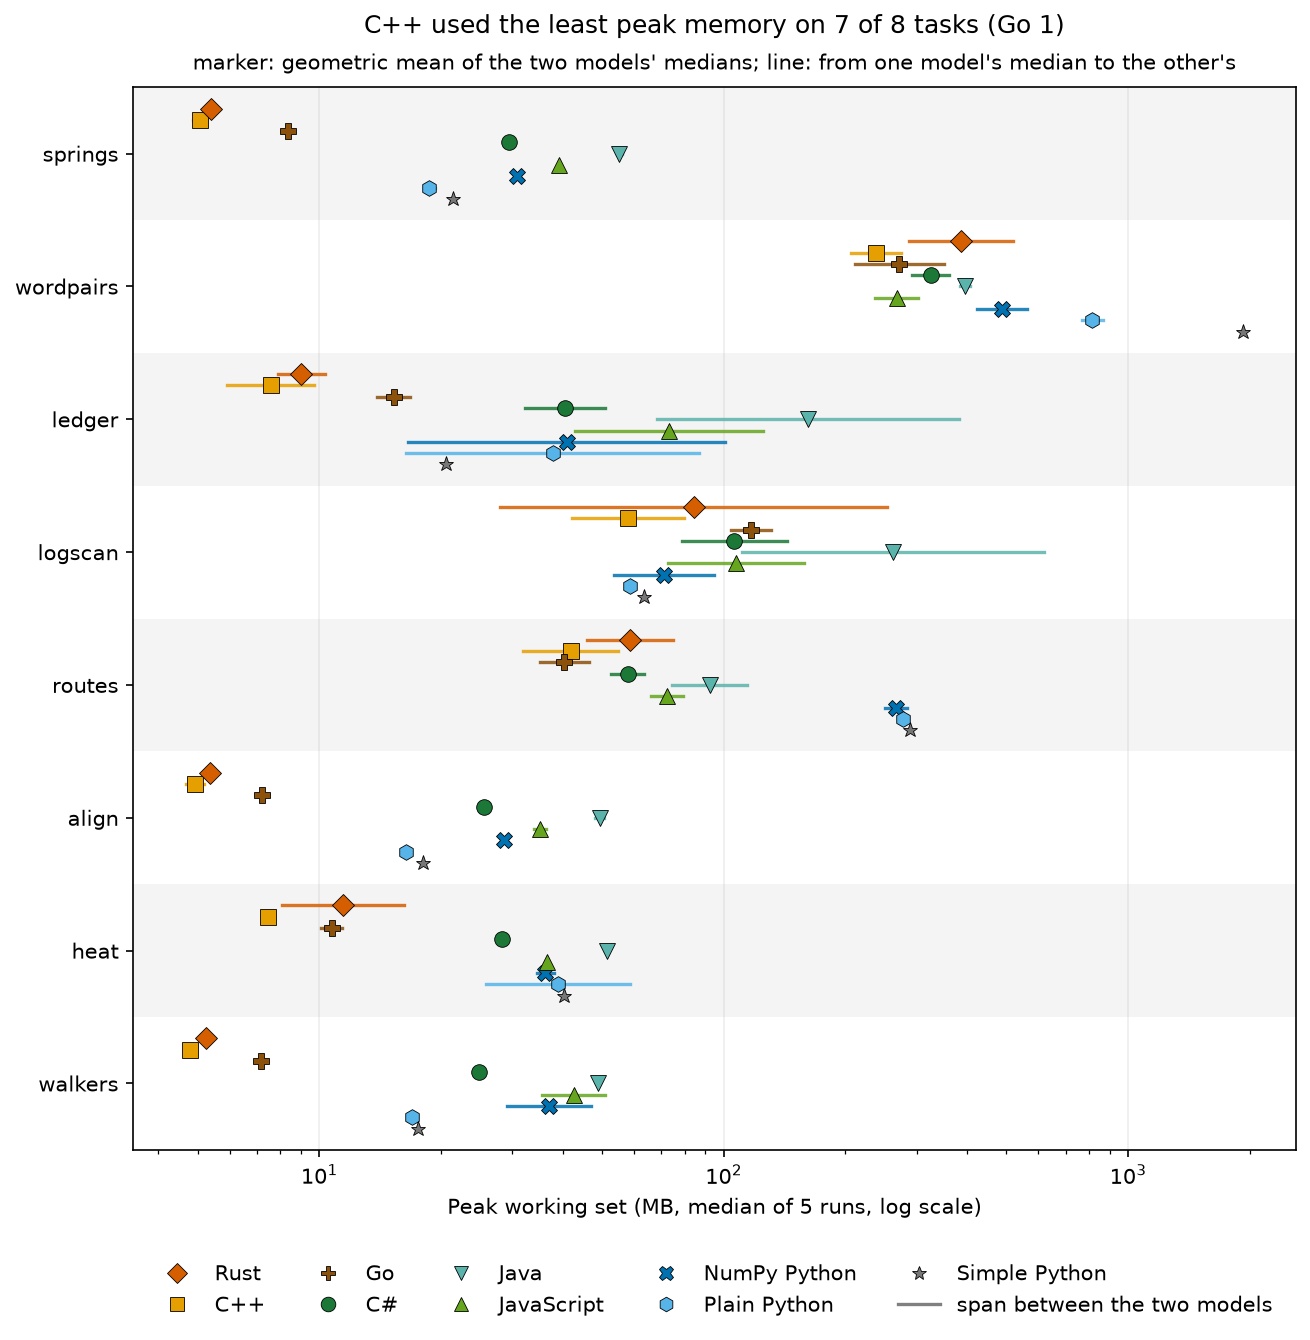

C++ used the least peak memory on 7 of 8 tasks (Go 1)


In [18]:
mem = full[full.author.isin(AUTHORS + ['reference'])].copy(); mem['memory_MB'] = mem.peak_working_set / 1e6
memory = mem.groupby(['task', 'author', 'variant']).memory_MB.median().reset_index(); memory['metric'] = 'peak working set'
memory.to_csv(DERIVED / 'memory.csv', index=False)
display(memory.pivot_table(index=['task', 'author'], columns='variant', values='memory_MB').reindex(columns=VERSIONS).reindex(TASKS, level='task').rename(columns=LABELS).round(1))
mem_comb = combine_authors(memory, 'memory_MB')
# Memory relative to the smallest of the nine versions on the same task and author.
mp = memory.pivot_table(index=['task', 'author'], columns='variant', values='memory_MB')
mp_sim = mp.copy()
for a in AUTHORS: mp_sim.loc[(slice(None), a), 'simple'] = mp.loc[(slice(None), 'reference'), 'simple'].to_numpy()
mp_rel = mp_sim.loc[(slice(None), AUTHORS), :].div(mp_sim.loc[(slice(None), AUTHORS), :].min(axis=1), axis=0)
display(mp_rel.groupby(level='author').agg(geom).T.reindex(VERSIONS).rename(index=LABELS).rename_axis('geometric-mean memory / smallest').round(2))
title, mem_best = winners_title(mem_comb.assign(gm=mem_comb.gm), 'used the least peak memory')
fig, ax = plt.subplots(figsize=(10, 9.2))
strip_by_task(ax, mem_comb, 'Peak working set (MB, median of 5 runs, log scale)')
ax.set_title(title, fontsize=12, pad=26)
ax.text(.5, 1.012, 'marker: geometric mean of the two models\' medians; line: from one model\'s median to the other\'s', transform=ax.transAxes, ha='center', va='bottom', fontsize=10)
ax.legend(handles=version_handles(ls='none') + [Line2D([0], [0], color='gray', lw=1.6, label='span between the two models')], loc='upper center', bbox_to_anchor=(.5, -.09), ncol=5, frameon=False)
savefig('memory_by_task.png')
print(title)

C++ needed the least memory in most rows, with Rust and Go close: relative to the smallest version on each task,
their geometric means were 1.0 to 1.1 for C++, 1.3 to 1.5 for Rust and 1.5 to 1.7 for Go. C# needed 3.1 to 3.8
times the smallest, JavaScript 3.6 to 5.5, plain Python 3.8 to 3.9, NumPy Python 4.0 to 5.4 and Java 5.4 to 8.7.

On small-data tasks the difference is mostly the runtime itself: 5 to 16 MB for the compiled languages against 15
to 60 MB for the virtual machines and Python. On large-data tasks it is how data is stored. The simple Python
wordpairs solution, which keeps about 4 million word pairs as Python objects, peaked at 1.9 GB; the models' versions
needed 200 to 870 MB. Java's virtual machine lets its heap grow before collecting garbage, so Terra's Java log
scanner peaked at 619 MB for a job its Rust did in 28 MB. Sonnet's Rust log scanner is the opposite case among the
compiled languages: it read the whole 228 MB log into memory before parsing and peaked at 254 MB.

## 14. Small inputs and start-up time

Wordpairs, routes and heat were also run at 1/256, 1/64, 1/16 and 1/4 of the benchmark size, three timed runs
each. Each panel is one task, with input size and run time on logarithmic axes and one line per version (geometric
mean of the two models). The first table gives each program's slope between the two largest sizes (1 means time
grows in proportion to input; near 0 means the time is mostly fixed cost); the second gives each version's time
relative to Rust at each size.

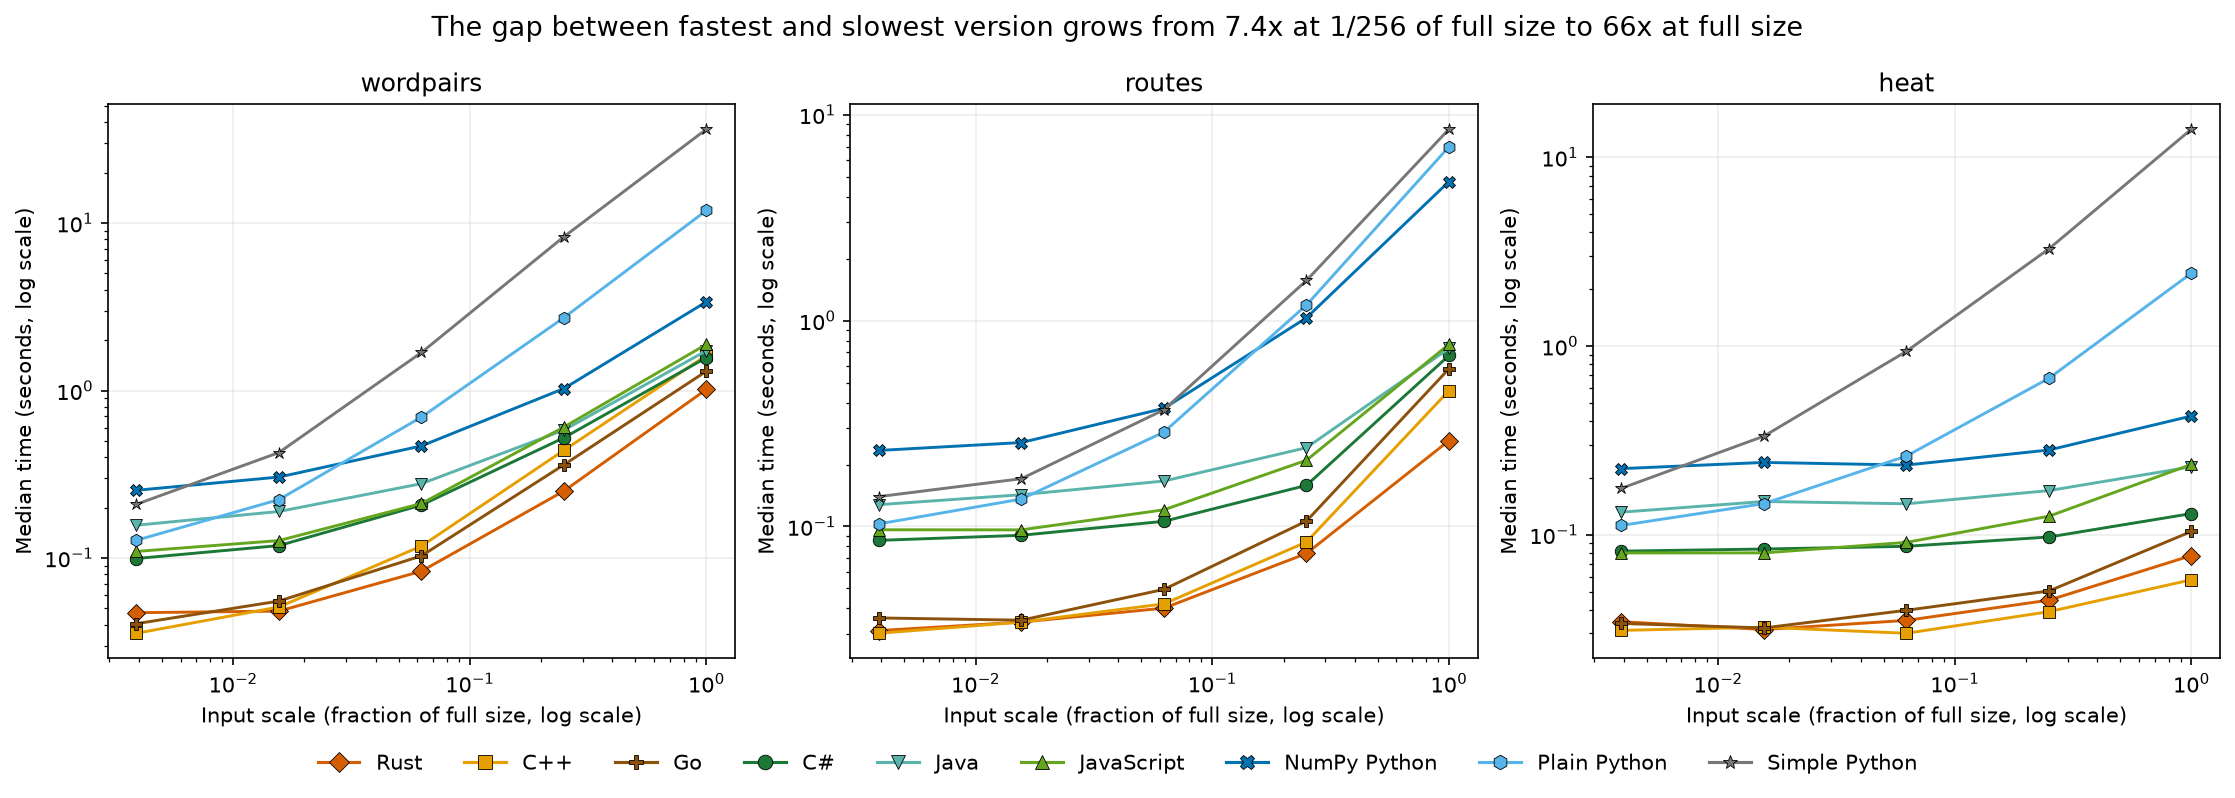

variant              Rust   C++    Go    C#  Java  JavaScript  NumPy Python  \
task      author                                                              
heat      reference   NaN   NaN   NaN   NaN   NaN         NaN           NaN   
          sonnet     0.17  0.18  0.56  0.09  0.19        0.48          0.31   
          terra      0.62  0.38  0.49  0.32  0.22        0.44          0.29   
routes    reference   NaN   NaN   NaN   NaN   NaN         NaN           NaN   
          sonnet     0.68  0.93  0.97  0.79  0.57        0.75          0.88   
          terra      1.14  1.51  1.49  1.31  1.03        1.12          1.32   
wordpairs reference   NaN   NaN   NaN   NaN   NaN         NaN           NaN   
          sonnet     0.92  0.82  0.80  0.67  0.63        0.67          0.80   
          terra      1.09  1.06  1.06  0.92  0.95        0.97          0.92   

variant              Plain Python  Simple Python  
task      author                                  
heat      reference           NaN           1.05  
          sonnet             0.89            NaN  
          terra              0.96            NaN  
routes    reference           NaN           1.22  
          sonnet             1.24            NaN  
          terra              1.32            NaN  
wordpairs reference           NaN           1.07  
          sonnet             1.05            NaN  
          terra              1.07            NaN

variant             Rust   C++    Go    C#  Java  JavaScript  NumPy Python  \
task      scale                                                              
heat      0.003906   1.0  0.90  0.98  2.37  3.81        2.31          6.47   
          0.015625   1.0  1.03  1.02  2.67  4.77        2.55          7.68   
          0.062500   1.0  0.85  1.13  2.47  4.15        2.59          6.65   
          0.250000   1.0  0.87  1.12  2.16  3.81        2.79          6.25   
          1.000000   1.0  0.74  1.34  1.67  2.95        3.04          5.49   
routes    0.003906   1.0  0.97  1.15  2.74  4.09        3.09          7.50   
          0.015625   1.0  1.00  1.02  2.64  4.16        2.81          7.45   
          0.062500   1.0  1.05  1.23  2.64  4.14        3.00          9.34   
          0.250000   1.0  1.14  1.44  2.14  3.26        2.84         13.95   
          1.000000   1.0  1.75  2.23  2.59  2.81        2.94         18.13   
wordpairs 0.003906   1.0  0.75  0.86  2.11  3.33        2.32          5.38   
          0.015625   1.0  1.06  1.15  2.46  3.93        2.64          6.32   
          0.062500   1.0  1.41  1.23  2.48  3.33        2.54          5.60   
          0.250000   1.0  1.75  1.44  2.08  2.31        2.41          4.09   
          1.000000   1.0  1.59  1.28  1.55  1.70        1.86          3.33   

variant             Plain Python  Simple Python  
task      scale                                  
heat      0.003906          3.24           5.09  
          0.015625          4.65          10.58  
          0.062500          7.43          26.65  
          0.250000         14.99          72.74  
          1.000000         31.38         181.71  
routes    0.003906          3.30           4.48  
          0.015625          3.96           4.97  
          0.062500          7.17           9.19  
          0.250000         16.10          21.18  
          1.000000         26.75          32.58  
wordpairs 0.003906          2.71           4.44  
          0.015625          4.63           8.85  
          0.062500          8.33          20.23  
          0.250000         10.85          33.02  
          1.000000         11.71          35.79

In [19]:
sw = pd.concat([sweep, runs[runs.task.isin(['wordpairs','routes','heat']) & runs.input.eq('full')]], ignore_index=True)
sw = sw[sw.author.isin(AUTHORS + ['reference']) & sw.status.eq('correct')].merge(ok, on=['author','task','variant'])
sw['scale'] = sw.apply(lambda r: entries[r.task, r.input]['scale'], axis=1)
sm = sw.groupby(['task','author','variant','scale']).wall_seconds.median().reset_index()
smc = sm.groupby(['task','variant','scale']).wall_seconds.agg(geom).rename('gm').reset_index()
SW_TASKS = ['wordpairs', 'routes', 'heat']
lo_scale, hi_scale = smc.scale.min(), smc.scale.max()
def spread(scale):
    d = smc[smc.scale.eq(scale)].groupby('task').gm.agg(lambda x: x.max() / x.min()); return geom(d)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, task in zip(axes, SW_TASKS):
    for v in VERSIONS:
        g = smc[(smc.task == task) & (smc.variant == v)].sort_values('scale')
        ax.plot(g.scale, g.gm, marker=MARKERS[v], ms=6, lw=1.4, color=COLORS[v], markeredgecolor='black', markeredgewidth=.4)
    ax.set(xscale='log', yscale='log', title=task, xlabel='Input scale (fraction of full size, log scale)', ylabel='Median time (seconds, log scale)')
fig.legend(handles=version_handles(), loc='upper center', bbox_to_anchor=(.5, 0.02), ncol=9, frameon=False)
fig.suptitle(f'The gap between fastest and slowest version grows from {spread(lo_scale):.1f}x at 1/{round(1/lo_scale)} of full size to {spread(hi_scale):.0f}x at full size', fontsize=13)
fig.tight_layout(); savefig('size_sweep.png')
slopes = []
for (t,a,v), g in sm.groupby(['task','author','variant']):
    g = g.sort_values('scale').tail(2)
    if len(g)==2: slopes.append(dict(task=t, author=a, variant=v, slope=np.log(g.wall_seconds.iloc[1]/g.wall_seconds.iloc[0])/np.log(g.scale.iloc[1]/g.scale.iloc[0])))
sl = pd.DataFrame(slopes)
display(sl.pivot_table(index=['task', 'author'], columns='variant', values='slope').reindex(columns=VERSIONS).rename(columns=LABELS).round(2))
pv = smc.pivot_table(index=['task', 'scale'], columns='variant', values='gm').reindex(columns=VERSIONS)
display(pv.div(pv['rust'], axis=0).rename(columns=LABELS).round(2))

At 1/256 of the benchmark size every version finishes within a few tenths of a second and the order follows the
start-up costs. Relative to Rust at that size, C++ and Go took about the same time, C# 2.4 times, JavaScript 2.6,
plain Python 3.1, Java 3.7 and NumPy Python 6.4. As inputs grow, the virtual machines' start-up and warm-up are
spread over more work and they close in (Java from 3.7 to 2.4 times Rust, C# from 2.4 to 1.9), while plain Python
falls behind (from 3.1 to 21 times). For a script that handles small files, start-up time can matter more than the
language's speed.

## 15. More cores

The walkers task asks for the walks to be split over a given number of workers. Each program ran with 1, 2, 4, 8
and 16 workers, three timed runs each. The left panel shows median run time (log scale), the right panel each
version's speed-up over its own one-worker time (geometric mean of the two models), with the dotted diagonal as a
perfect speed-up and the vertical line at the laptop's six performance cores. The table gives both models
separately, with CPU time divided by wall time (how many cores were busy on average).

time by workers             1      2     4     8     16
variant       author                                   
Rust          sonnet      0.13   0.08  0.06  0.05  0.05
              terra       0.29   0.20  0.12  0.08  0.07
C++           sonnet      0.09   0.06  0.05  0.04  0.05
              terra       0.35   0.18  0.11  0.09  0.07
Go            sonnet      0.13   0.07  0.07  0.05  0.05
              terra       0.33   0.20  0.13  0.09  0.07
C#            sonnet      0.16   0.12  0.12  0.10  0.10
              terra       0.42   0.23  0.17  0.15  0.13
Java          sonnet      0.24   0.23  0.28  0.34  0.45
              terra       0.42   0.35  0.26  0.25  0.29
JavaScript    sonnet      0.46   0.29  0.23  0.26  0.25
              terra       1.07   0.63  0.51  0.39  0.46
NumPy Python  sonnet      0.96   0.82  0.73  0.86  0.85
              terra       1.78   1.30  1.18  1.08  1.44
Plain Python  sonnet     14.38   7.27  4.55  2.99  2.50
              terra      17.67   9.86  5.82  3.72  3.26
Simple Python reference  18.39  10.10  5.85  3.85  3.20

speedup by workers        1     2     4     8     16
variant       author                                
Rust          sonnet     1.0  1.50  1.99  2.34  2.52
              terra      1.0  1.49  2.47  3.49  4.02
C++           sonnet     1.0  1.45  1.75  2.06  2.03
              terra      1.0  1.95  3.15  4.05  5.08
Go            sonnet     1.0  1.89  1.93  2.64  2.78
              terra      1.0  1.66  2.59  3.86  4.40
C#            sonnet     1.0  1.39  1.41  1.64  1.63
              terra      1.0  1.81  2.47  2.80  3.32
Java          sonnet     1.0  1.07  0.86  0.70  0.54
              terra      1.0  1.22  1.64  1.72  1.46
JavaScript    sonnet     1.0  1.58  2.01  1.77  1.86
              terra      1.0  1.71  2.12  2.77  2.32
NumPy Python  sonnet     1.0  1.16  1.30  1.10  1.12
              terra      1.0  1.37  1.51  1.65  1.24
Plain Python  sonnet     1.0  1.98  3.16  4.81  5.75
              terra      1.0  1.79  3.04  4.74  5.41
Simple Python reference  1.0  1.82  3.14  4.78  5.74

cpu_wall by workers        1     2     4     8      16
variant       author                                  
Rust          sonnet     0.86  1.28  2.21  2.62   3.28
              terra      0.93  1.76  2.79  4.44   6.18
C++           sonnet     0.85  1.12  1.78  1.38   4.47
              terra      0.97  1.74  2.81  4.50   6.12
Go            sonnet     0.84  1.16  1.92  1.86   4.92
              terra      1.00  1.66  2.95  4.41   5.45
C#            sonnet     0.95  1.19  1.29  1.61   3.29
              terra      0.98  1.62  2.43  3.43   4.36
Java          sonnet     1.17  1.31  2.06  4.20   9.83
              terra      1.07  1.81  2.14  3.51   8.27
JavaScript    sonnet     1.01  1.62  2.89  4.85   8.83
              terra      0.99  2.02  3.49  7.05  12.57
NumPy Python  sonnet     0.95  1.61  2.74  5.37   5.06
              terra      0.97  1.65  2.81  4.89   7.37
Plain Python  sonnet     0.98  1.90  3.70  6.91  12.53
              terra      0.98  1.91  3.76  7.14  12.78
Simple Python reference  0.98  1.93  3.75  7.20  13.23

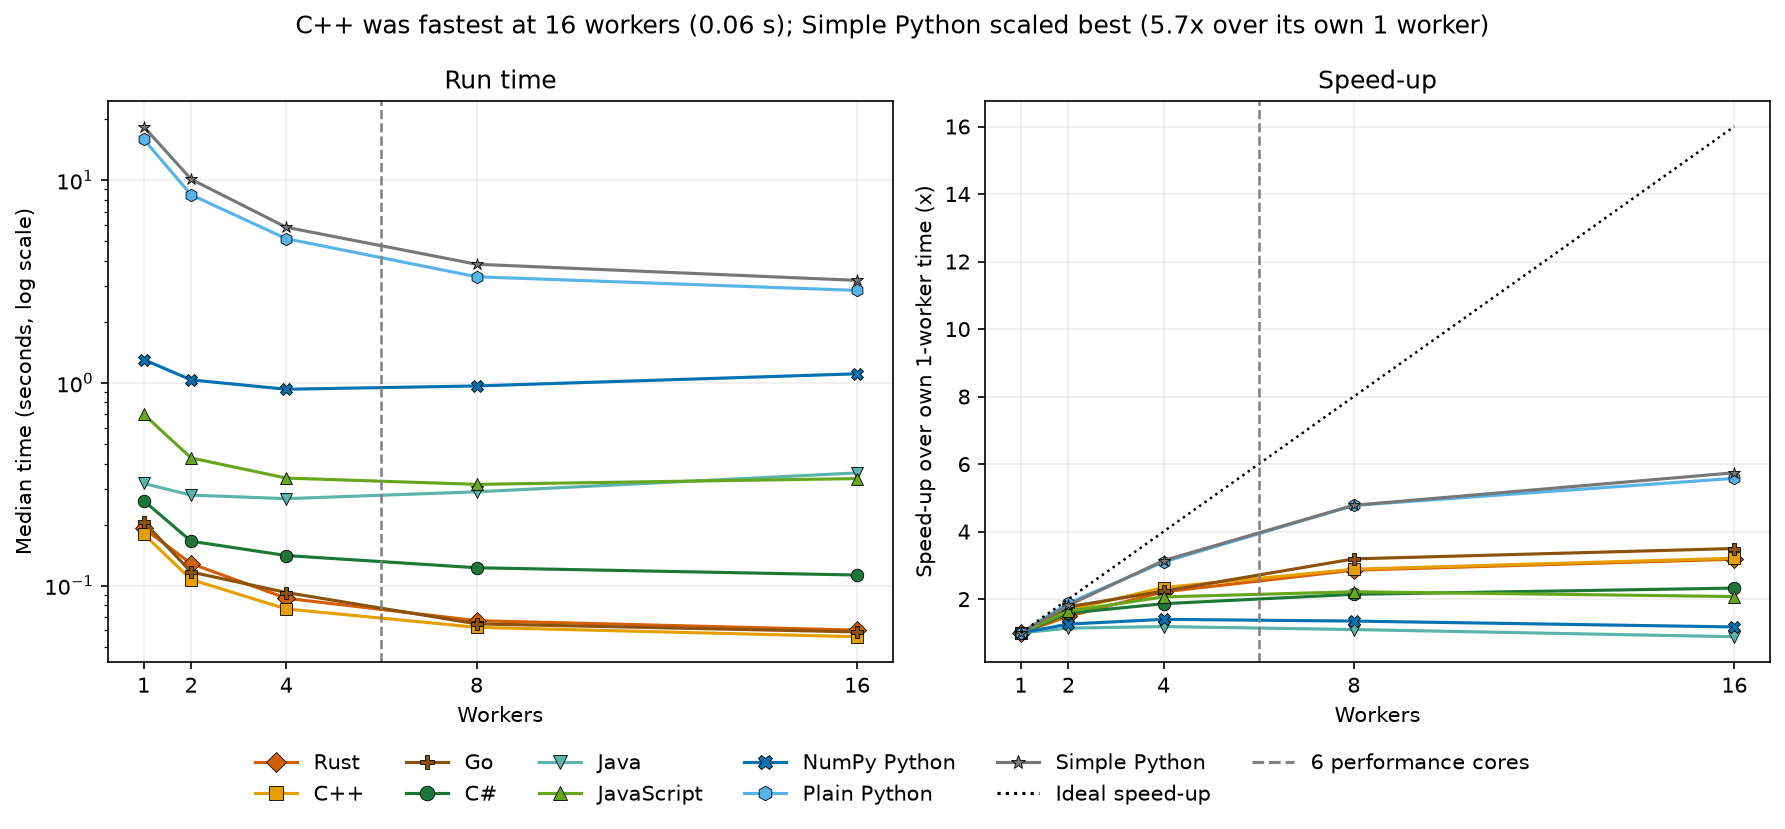

6 cpp simple


In [20]:
sc = scaling[scaling.status.eq('correct')].merge(ok, on=['author','task','variant'])
scm = sc.groupby(['author','variant','workers']).agg(time=('wall_seconds','median'), cpu_wall=('cpu_wall_ratio','median')).reset_index()
one = scm[scm.workers == 1].set_index(['author', 'variant']).time
scm['speedup'] = [one[(r.author, r.variant)] / r.time for r in scm.itertuples()]
for col in ['time', 'speedup', 'cpu_wall']:
    display(scm.pivot_table(index=['variant', 'author'], columns='workers', values=col).reindex(VERSIONS, level='variant').rename(index=LABELS, level='variant').round(2).rename_axis(columns=f'{col} by workers'))
n_pcores = len(machine['p_cores']) // 2   # P-cores have two threads each
scv = scm.groupby(['variant', 'workers']).agg(time=('time', geom), speedup=('speedup', geom)).reset_index()
t16 = scv[scv.workers == 16].set_index('variant'); fast16 = t16.time.idxmin(); best_scale = t16.speedup.idxmax()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for v in VERSIONS:
    g = scv[scv.variant == v].sort_values('workers')
    for ax, col in zip(axes, ['time', 'speedup']): ax.plot(g.workers, g[col], marker=MARKERS[v], ms=6, lw=1.5, color=COLORS[v], markeredgecolor='black', markeredgewidth=.4)
axes[0].set(yscale='log', ylabel='Median time (seconds, log scale)', title='Run time')
axes[1].plot([1, 16], [1, 16], color='black', ls=':', lw=1.2); axes[1].set(ylabel='Speed-up over own 1-worker time (x)', title='Speed-up')
for ax in axes: ax.axvline(n_pcores, color='gray', ls='--', lw=1.2); ax.set(xlabel='Workers', xticks=[1, 2, 4, 8, 16])
fig.suptitle(f'{LABELS[fast16]} was fastest at 16 workers ({t16.time[fast16]:.2f} s); {LABELS[best_scale]} scaled best ({t16.speedup[best_scale]:.1f}x over its own 1 worker)', fontsize=12)
fig.legend(handles=version_handles() + [Line2D([0], [0], color='black', ls=':', label='Ideal speed-up'), Line2D([0], [0], color='gray', ls='--', label=f'{n_pcores} performance cores')], loc='upper center', bbox_to_anchor=(.5, 0.02), ncol=6, frameon=False)
fig.tight_layout(); savefig('walkers_scaling.png')
print(n_pcores, fast16, best_scale)

Plain Python cannot run Python code on several cores within one process in the standard build used here, so both
models started one process per worker; with 16 workers it ran 5.4 to 5.7 times faster than with one. The compiled
and virtual-machine languages used threads and gained 1.5 to 5 times, less in relative terms because their
one-worker times (0.09 to 1.1 s) were already close to their start-up floors. Sonnet's Java became slower with more
threads (0.24 s with one, 0.45 s with sixteen), and the NumPy versions barely changed. Even with 16 processes, the
fastest Python program (0.86 s, NumPy) was slower than every model's C++, Rust and Go on a single thread.

## 16. Code size and build time

The left panel shows the total source size over the eight tasks per version and model, in kilobytes; line counts
would mislead, because Terra often wrote several statements on one line (its Go ledger is 33 lines and 2.8 KB). The
right panel shows each compiled language's median build time from clean (median of three builds per program) and
after a one-line change. JavaScript and Python have no build step.

source bytes         Rust      C++      Go       C#     Java  JavaScript  \
task      author                                                           
springs   sonnet   2087.0   3535.0  1564.0   3349.0   2200.0      1545.0   
          terra    2011.0   1182.0  1144.0   1402.0   1441.0      1034.0   
wordpairs sonnet   6596.0   7115.0  5292.0   7788.0   7975.0      6513.0   
          terra    3097.0   2413.0  2023.0   3377.0   3434.0      2994.0   
ledger    sonnet  11856.0  11769.0  9151.0  16677.0  17946.0     14512.0   
          terra    2964.0   2364.0  2808.0   2641.0   3619.0      2128.0   
logscan   sonnet   7209.0   8982.0  7024.0  10364.0  10114.0      8087.0   
          terra    3611.0   3362.0  1846.0   2116.0   2354.0      1368.0   
routes    sonnet   5611.0   3721.0  2554.0   3675.0   3572.0      2437.0   
          terra    2498.0   1702.0  2093.0   1892.0   1898.0      1659.0   
align     sonnet   3656.0   2805.0  1974.0   2762.0   2655.0      1940.0   
          terra    2327.0   1462.0  1282.0   1217.0   1397.0      1208.0   
heat      sonnet   3136.0   2809.0  1902.0   3453.0   2680.0      2029.0   
          terra    2040.0   1232.0  1549.0   1463.0   1584.0      1315.0   
walkers   sonnet   2972.0   2185.0  1722.0   2207.0   2345.0      3498.0   
          terra    2579.0   1837.0  1579.0   1752.0   1930.0      3840.0   

source bytes      NumPy Python  Plain Python  
task      author                              
springs   sonnet        1322.0        1157.0  
          terra         1378.0        1238.0  
wordpairs sonnet        7587.0        2022.0  
          terra         1783.0        1264.0  
ledger    sonnet        4911.0        2739.0  
          terra         1610.0        1610.0  
logscan   sonnet        2623.0        1998.0  
          terra         2074.0        1526.0  
routes    sonnet        4204.0        1848.0  
          terra         1616.0        1344.0  
align     sonnet        2069.0        1719.0  
          terra         1743.0        1888.0  
heat      sonnet        1926.0        3131.0  
          terra         1643.0        1427.0  
walkers   sonnet        4941.0        2288.0  
          terra         3177.0        2063.0

code lines         Rust    C++     Go     C#   Java  JavaScript  NumPy Python  \
task      author                                                                
springs   sonnet   61.0   91.0   82.0   79.0   51.0        45.0          47.0   
          terra    46.0   24.0   17.0   21.0   19.0        14.0          37.0   
wordpairs sonnet  212.0  205.0  295.0  243.0  218.0       208.0         178.0   
          terra    80.0   27.0   11.0   16.0   14.0        17.0          53.0   
ledger    sonnet  395.0  371.0  554.0  505.0  515.0       558.0         129.0   
          terra    61.0   44.0   33.0   35.0   53.0        40.0          42.0   
logscan   sonnet  246.0  261.0  362.0  276.0  250.0       258.0          77.0   
          terra    88.0   48.0    9.0   10.0   16.0        19.0          48.0   
routes    sonnet  178.0  112.0  141.0  109.0   97.0        89.0         125.0   
          terra    68.0   21.0   19.0   16.0   16.0        14.0          47.0   
align     sonnet   99.0   89.0  113.0   88.0   75.0        72.0          58.0   
          terra    52.0   23.0   17.0   14.0   19.0        14.0          44.0   
heat      sonnet   86.0   72.0   95.0   84.0   63.0        56.0          44.0   
          terra    49.0   35.0   83.0   27.0   30.0        23.0          37.0   
walkers   sonnet   84.0   60.0   86.0   62.0   56.0        95.0         140.0   
          terra    53.0   33.0   17.0   23.0   26.0        78.0          77.0   

code lines        Plain Python  
task      author                
springs   sonnet          42.0  
          terra           33.0  
wordpairs sonnet          64.0  
          terra           37.0  
ledger    sonnet          85.0  
          terra           42.0  
logscan   sonnet          62.0  
          terra           34.0  
routes    sonnet          60.0  
          terra           40.0  
align     sonnet          51.0  
          terra           56.0  
heat      sonnet          84.0  
          terra           41.0  
walkers   sonnet          78.0  
          terra           59.0

clean_median      Rust   C++    Go    C#  Java
task      author                              
springs   sonnet  2.74  4.46  5.61  3.78  0.85
          terra   0.98  3.60  4.94  3.33  0.78
wordpairs sonnet  3.01  3.54  6.60  5.16  1.11
          terra   1.08  3.79  4.92  3.31  0.92
ledger    sonnet  3.59  3.62  4.77  3.65  1.05
          terra   9.56  5.86  5.74  3.49  0.94
logscan   sonnet  3.21  3.81  4.60  3.31  0.95
          terra   9.75  3.76  4.89  3.31  0.89
routes    sonnet  2.80  3.34  4.70  3.44  0.80
          terra   1.13  3.15  4.88  3.36  0.78
align     sonnet  2.84  3.40  4.60  3.48  0.86
          terra   1.00  3.68  4.73  3.74  0.82
heat      sonnet  2.47  3.25  4.84  3.33  0.81
          terra   0.96  3.90  4.95  3.46  0.79
walkers   sonnet  2.80  3.44  4.99  3.74  0.89
          terra   1.18  3.86  5.03  3.72  0.85

incremental_seconds  Rust   C++    Go    C#  Java
task      author                                 
springs   sonnet     2.56  4.00  0.22  2.65  0.81
          terra      0.83  3.71  0.22  2.68  0.84
wordpairs sonnet     2.81  3.98  0.24  3.35  1.49
          terra      0.96  3.83  0.23  2.38  0.82
ledger    sonnet     3.23  3.77  0.22  2.68  1.01
          terra      1.87  6.08  0.30  2.47  0.86
logscan   sonnet     3.01  3.52  0.32  2.54  1.02
          terra      1.19  3.81  0.25  2.46  0.83
routes    sonnet     2.50  3.28  0.31  2.60  0.78
          terra      0.84  3.20  0.25  2.39  0.75
align     sonnet     2.56  3.36  0.24  2.59  0.74
          terra      0.95  3.58  0.32  2.67  0.70
heat      sonnet     2.38  3.22  0.30  2.63  0.80
          terra      0.79  3.86  0.22  2.75  0.81
walkers   sonnet     2.75  3.30  0.24  2.55  0.83
          terra      0.96  4.12  0.22  2.51  0.85

bytes        code_lines      
author       sonnet  terra     sonnet terra
variant                                    
Rust          43123  21127       1361   497
C++           42921  15554       1261   255
Go            31183  14324       1728   206
C#            50275  15860       1446   162
Java          49487  17657       1325   193
JavaScript    40561  15546       1381   219
NumPy Python  29583  15024        798   385
Plain Python  16902  12360        526   342

,author,variant,clean,incremental
0,sonnet,cpp,3.490794,3.437577
1,sonnet,csharp,3.564701,2.616908
2,sonnet,go,4.802367,0.242576
3,sonnet,java,0.876185,0.820217
4,sonnet,js,NaN,NaN
5,sonnet,rust,2.824121,2.654877
6,terra,cpp,3.774804,3.820951
7,terra,csharp,3.410870,2.491430
8,terra,go,4.927593,0.239401
9,terra,java,0.831108,0.828926


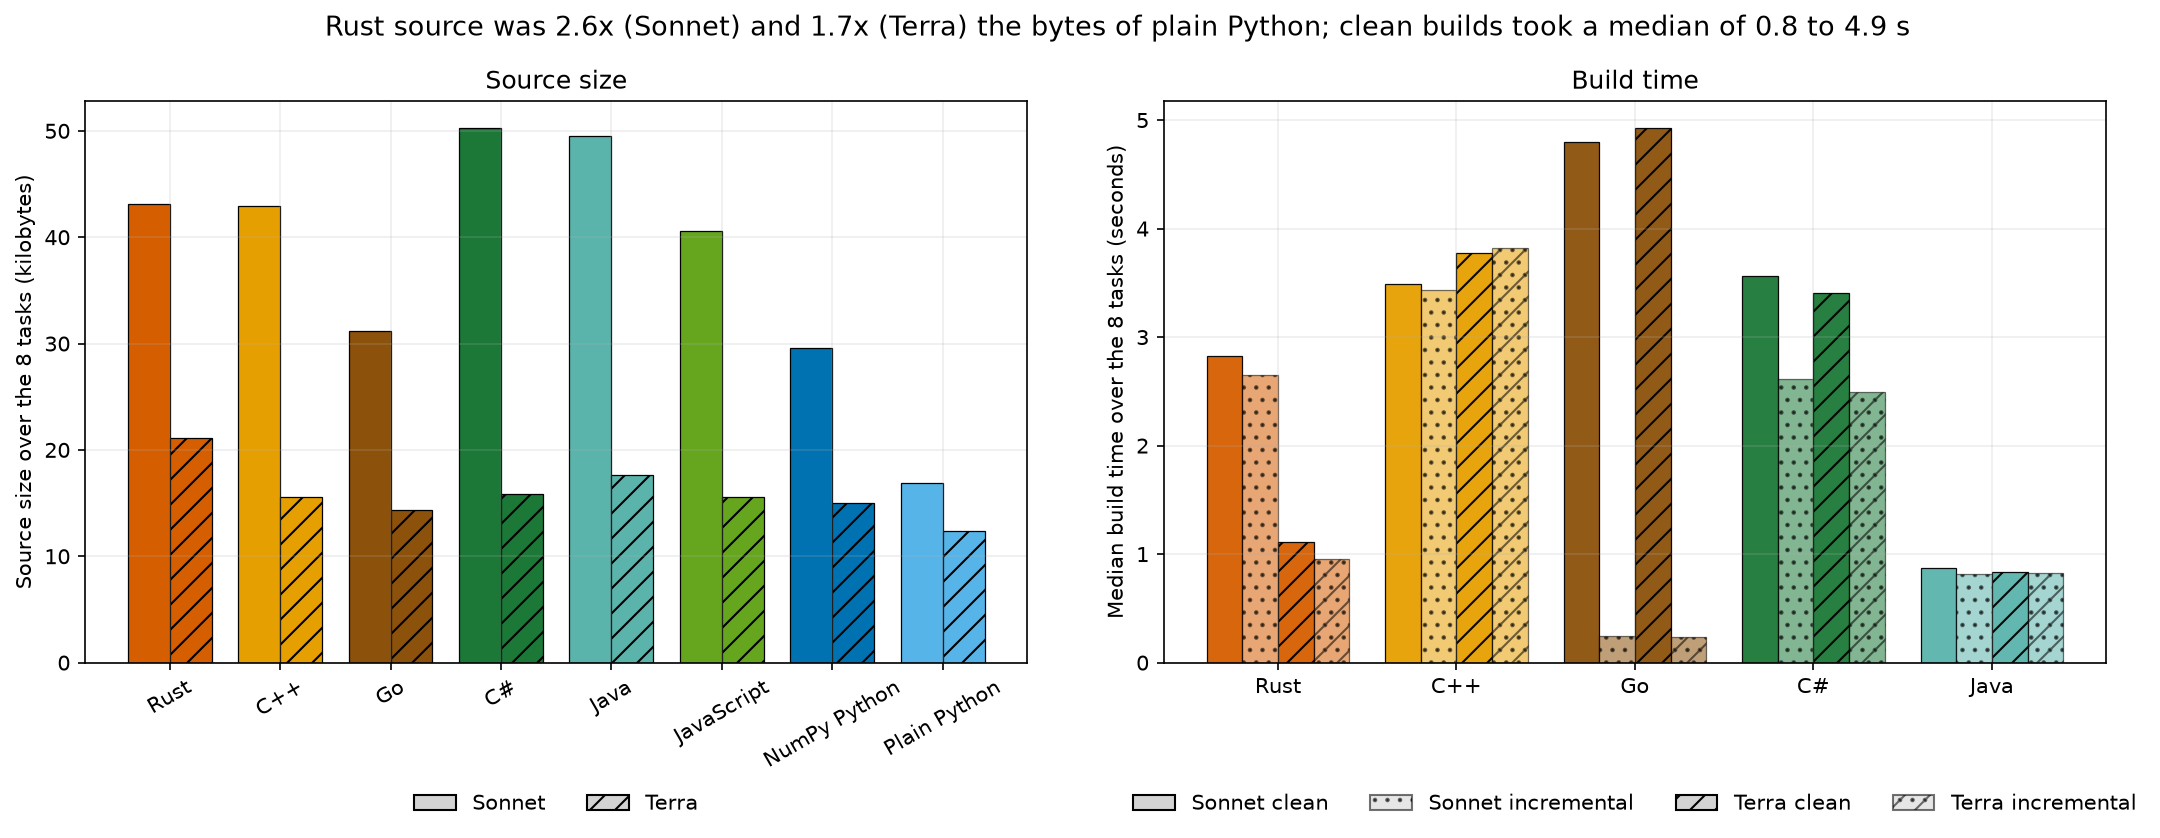

2.551354869246243 1.709304207119741 0.8311076999962097 4.927593350003008


In [21]:
loc_main = loc[loc.author.isin(AUTHORS)].groupby(['author', 'task', 'variant']).agg(code_lines=('code_lines', 'sum'), bytes=('bytes', 'sum')).reset_index()
build_main = builds[builds.author.isin(AUTHORS)].copy()
build_main['clean_median'] = build_main.clean_seconds.map(lambda x: np.median(json.loads(x)) if isinstance(x, str) and json.loads(x) else np.nan)
BUILT = ['rust', 'cpp', 'go', 'csharp', 'java']      # JavaScript has no build step
for col, name in [('bytes', 'source bytes'), ('code_lines', 'code lines')]:
    display(loc_main.pivot_table(index=['task', 'author'], columns='variant', values=col).reindex(columns=MODEL_VERSIONS).reindex(TASKS, level='task').rename(columns=LABELS).rename_axis(columns=name))
for col in ['clean_median', 'incremental_seconds']:
    display(build_main.pivot_table(index=['task', 'author'], columns='variant', values=col).reindex(columns=LANGS[:5]).reindex(TASKS, level='task').rename(columns=LABELS).round(2).rename_axis(columns=col))
tot = loc_main.groupby(['author', 'variant'])[['bytes', 'code_lines']].sum()
display(tot.unstack('author').reindex(MODEL_VERSIONS).rename(index=LABELS))
r_s = tot.bytes['sonnet', 'rust'] / tot.bytes['sonnet', 'plain']; r_t = tot.bytes['terra', 'rust'] / tot.bytes['terra', 'plain']
bt = build_main.groupby(['author', 'variant']).agg(clean=('clean_median', 'median'), incremental=('incremental_seconds', 'median')).reset_index()
display(bt)
lo, hi = bt.clean.min(), bt.clean.max()
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
x = np.arange(len(MODEL_VERSIONS)); w = .38
for k, a in enumerate(AUTHORS):
    d = [tot.bytes[a, v] / 1000 for v in MODEL_VERSIONS]
    axes[0].bar(x + (k - .5) * w, d, w, color=[COLORS[v] for v in MODEL_VERSIONS], edgecolor='black', linewidth=.6, hatch='//' if a == 'terra' else '')
axes[0].set(xticks=x, xticklabels=[LABELS[v] for v in MODEL_VERSIONS], ylabel='Source size over the 8 tasks (kilobytes)', title='Source size')
axes[0].tick_params(axis='x', rotation=30)
x2 = np.arange(len(BUILT)); w2 = .2
for k, (a, col) in enumerate([(a, c) for a in AUTHORS for c in ['clean', 'incremental']]):
    d = [bt[(bt.author == a) & (bt.variant == v)][col].iloc[0] for v in BUILT]
    axes[1].bar(x2 + (k - 1.5) * w2, d, w2, color=[COLORS[v] for v in BUILT], edgecolor='black', linewidth=.6, hatch=('//' if a == 'terra' else '') + ('..' if col == 'incremental' else ''), alpha=.95 if col == 'clean' else .55)
axes[1].set(xticks=x2, xticklabels=[LABELS[v] for v in BUILT], ylabel='Median build time over the 8 tasks (seconds)', title='Build time')
axes[0].legend(handles=[Patch(facecolor='lightgray', edgecolor='black', label='Sonnet'), Patch(facecolor='lightgray', edgecolor='black', hatch='//', label='Terra')], loc='upper center', bbox_to_anchor=(.5, -.2), ncol=2, frameon=False)
axes[1].legend(handles=[Patch(facecolor='lightgray', edgecolor='black', label='Sonnet clean'), Patch(facecolor='lightgray', edgecolor='black', alpha=.55, hatch='..', label='Sonnet incremental'),
                        Patch(facecolor='lightgray', edgecolor='black', hatch='//', label='Terra clean'), Patch(facecolor='lightgray', edgecolor='black', alpha=.55, hatch='//..', label='Terra incremental')],
               loc='upper center', bbox_to_anchor=(.5, -.2), ncol=4, frameon=False)
fig.suptitle(f'Rust source was {r_s:.1f}x (Sonnet) and {r_t:.1f}x (Terra) the bytes of plain Python; clean builds took a median of {lo:.1f} to {hi:.1f} s', fontsize=13)
fig.tight_layout(); savefig('code_and_build.png')
print(r_s, r_t, lo, hi)

Sonnet wrote more code than Terra in every language: 43 KB of Rust and C++ against 17 KB of plain Python, and 21 KB
of Rust and 16 KB of C++ against 12 KB of plain Python for Terra. Much of Sonnet's extra code is hand-written parsing
and hash tables, which is also where its speed came from. Building from clean took about 1 s for Java, 1 to 10 s
for Rust (the longest when the JSON or pattern libraries were compiled too), 3 to 6 s for C++ and C#, and 5 to 7 s
for Go, whose clean build recompiles its standard library; a Go rebuild after a one-line change took 0.2 s.

## 17. The two models, and two larger models on heat

The first table gives, per version, the geometric mean over tasks of Sonnet's time divided by Terra's, and how many
tasks each model's program was faster. The second compares the heat programs of all four models, including those by
Claude Opus 5.5 and GPT-6.1 Sol, which wrote heat in Rust and Python only.

In [22]:
a = median[median.author.isin(AUTHORS)].pivot(index=['task','variant'],columns='author',values='median').dropna()
a['Sonnet / Terra'] = a.sonnet/a.terra; a['faster'] = np.where(a['Sonnet / Terra']<1,'Sonnet',np.where(a['Sonnet / Terra']>1,'Terra','tie'))
display(a.round(3).reindex(VERSIONS, level='variant').sort_index(level='task', sort_remaining=False))
cmp = a.groupby('variant').agg(geometric_mean=('Sonnet / Terra', geom), sonnet_faster=('faster', lambda x: int((x == 'Sonnet').sum())), terra_faster=('faster', lambda x: int((x == 'Terra').sum())), tasks=('faster', 'size'))
display(cmp.reindex(MODEL_VERSIONS).rename(index=LABELS).round(3))

author             sonnet   terra  Sonnet / Terra  faster
task      variant                                        
align     rust      0.074   0.123           0.599  Sonnet
          cpp       0.085   0.534           0.159  Sonnet
          go        0.110   0.128           0.859  Sonnet
          csharp    0.375   0.349           1.076   Terra
          java      0.284   0.275           1.033   Terra
...                   ...     ...             ...     ...
wordpairs csharp    1.050   2.357           0.446  Sonnet
          java      1.161   2.579           0.450  Sonnet
          js        1.270   2.808           0.452  Sonnet
          fast      2.072   5.546           0.374  Sonnet
          plain    11.072  12.801           0.865  Sonnet

[64 rows x 4 columns]

,geometric_mean,sonnet_faster,terra_faster,tasks
variant,,,,
Rust,0.518,7,1,8
C++,0.265,8,0,8
Go,0.408,7,1,8
C#,0.468,7,1,8
Java,0.555,6,2,8
JavaScript,0.488,7,1,8
NumPy Python,0.594,6,2,8
Plain Python,0.665,7,1,8


In [23]:
if {'opus','sol'}.issubset(set(median[median.task.eq('heat')].author)):
    display(median[(median.task=='heat') & median.author.isin(['opus','sol','sonnet','terra'])].pivot(index='variant',columns='author',values='median').reindex(['plain','fast','rust']).round(4))
else: print('Opus and Sol pilot programs were not both measured.')

author,opus,sol,sonnet,terra
variant,,,,
plain,0.6430,0.8742,0.9026,6.5658
fast,0.3835,0.3486,0.4281,0.4233
rust,0.0417,0.0440,0.0566,0.1064


Sonnet's programs were faster than Terra's in most languages, and the gap was largest where a task needed custom
parsing: on ledger, Sonnet's C++, Go and JavaScript took 0.7, 0.7 and 1.2 s against Terra's 9.8, 6.6 and 7.3 s.
Sonnet made more specialised choices (hand-written parsers and hash tables, a bucket queue for routes, a rewritten
alignment recurrence, the packed-integer heat grid); Terra wrote plainer programs closer to the textbook method.
Both styles gave correct programs; Sonnet's extra effort bought speed. One program per model and task is a small
sample of each model's behaviour, so these differences describe these sessions, not the models in general.

The two larger models wrote faster heat programs in Rust: 0.042 s for Opus 5.5 and 0.044 s for Sol, against 0.057 s
for Sonnet and 0.106 s for Terra. Their plain Python took 0.64 and 0.87 s, also with packed integers.

## 18. Error analysis: slow choices, not wrong answers

No program gave a wrong answer, so this section looks at the next most useful thing: programs that were correct but
much slower or larger than they needed to be, and why. The cases are all the large anomalies in the tables above,
found by comparing each model's versions with each other and with the other model's.

**Terra's ledger was slower in C++, Go and JavaScript than in Python.** Terra's C++ ledger took 9.8 s, its Go 6.6 s
and its JavaScript 7.3 s, while its plain Python took 7.2 s and its Rust 1.3 s. All three hand every line to a
general JSON library. The C++ version builds a full nlohmann/json object tree for each of the million lines:

In [24]:
show_code('terra', 'ledger', 'cpp', 13, 24)

  13      ios::sync_with_stdio(false); cin.tie(nullptr);
  14      ifstream f(argv[1], ios::binary); string line;
  15      getline(f, line); auto first = json::parse(line);
  16      unordered_map<string,int64_t> rates;
  17      for (auto it=first["rates"].begin(); it!=first["rates"].end(); ++it) rates.emplace(it.key(), it.value().get<int64_t>());
  18      unordered_map<string,int64_t> accounts; unordered_map<string,Stat> channels;
  19      int64_t count=0, net=0;
  20      while (getline(f,line)) {
  21          auto j=json::parse(line);
  22          auto &type=j["type"].get_ref<const string&>();
  23          if(type=="void") continue;
  24          bool skip=false; for(auto &tag:j["tags"]) if(tag=="test") {skip=true; break;}


The Go version decodes each line into a map of raw fields and then decodes each field again with Go's
reflection-based `encoding/json`:

In [25]:
show_code('terra', 'ledger', 'go', 16, 24)

  16   r:=bufio.NewReaderSize(f,1<<20); line,err:=r.ReadBytes('\n'); if err!=nil {panic(err)}
  17   var first map[string]json.RawMessage; if err=json.Unmarshal(line,&first); err!=nil {panic(err)}; rates:=make(map[string]int64); if err=json.Unmarshal(first["rates"],&rates); err!=nil {panic(err)}
  18   accounts:=make(map[string]int64); channels:=make(map[string]*stat); var count,net int64
  19   for { line,err=r.ReadBytes('\n'); if err==io.EOF && len(line)==0 {break}; if err!=nil && err!=io.EOF {panic(err)}
  20    var fields map[string]json.RawMessage; if e:=json.Unmarshal(line,&fields); e!=nil {panic(e)}
  21    var t transaction
  22    for _, field:=range []struct{key string; dest any}{{"account",&t.Account},{"type",&t.Type},{"amount",&t.Amount},{"currency",&t.Currency},{"tags",&t.Tags}} {if e:=json.Unmarshal(fields[field.key],field.dest); e!=nil {panic(e)}}
  23    var meta map[string]json.RawMessage; if e:=json.Unmarshal(fields["meta"],&meta); e!=nil {panic(e)}; if e:=json.Unmars

The JavaScript version calls `JSON.parse` per line and does every amount in `BigInt` arithmetic. Sonnet instead
wrote a small byte-level scanner in each language that reads only the needed fields, and its C++, Go and JavaScript
ledgers took 0.66, 0.65 and 1.2 s. On this task the choice of parser mattered more than the language.

**Terra's C++ trailed its Rust on wordpairs and align.** On wordpairs Terra's C++ took 3.6 s against 1.2 s for its
Rust and 0.73 s for Sonnet's C++. It keeps words in the standard `std::unordered_map`, which Microsoft's library
implements as a table of linked nodes; Sonnet's C++ wrote its own open-addressing table. On align Terra's C++ took
0.53 s against 0.12 s for its Rust, with the same row-by-row recurrence; its inner loop takes the minimum of three
values with `std::min` over an initializer list, and whether the compiler handled that loop worse is a possible
explanation this study did not test.

**Terra's Go log scanner checked each line with Go's `regexp` package** and took 3.4 s, more than its C++ (1.5 s)
and C# (2.3 s) and close to its Python (4.0 s). Sonnet's Go checked the format by hand, with no regular expression,
and took 0.45 s. The gap fits the matching being the cost, but the matcher was not timed separately.

**Some NumPy versions were no faster, or slower, than plain Python.** On ledger, parsing is most of the work and
NumPy cannot speed it up, so copying the parsed fields into arrays is extra work: Sonnet's NumPy ledger took 8.5 s
against 6.6 s for its plain one. Terra's NumPy routes (10.4 s against 8.6 s) read the
road list with `np.fromstring`:

In [26]:
show_code('terra', 'routes', 'fast', 7, 21)

   7      with open(sys.argv[1], 'rb') as f:
   8          n, m, q = map(int, f.readline().split())
   9          data = np.fromstring(f.read(), dtype=np.int64, sep=' ')
  10      edges = data[:3*m].reshape(m, 3)
  11      # Convert once to native integers so the graph traversal avoids NumPy scalar overhead.
  12      us = edges[:, 0].tolist()
  13      vs = edges[:, 1].tolist()
  14      ws = edges[:, 2].tolist()
  15      sources = data[3*m:3*m+q].tolist()
  16      del edges, data
  17      adj = [[] for _ in range(n)]
  18      for u, v, w in zip(us, vs, ws):
  19          adj[u].append((v, w))
  20          adj[v].append((u, w))
  21      del us, vs, ws


Timed separately on the benchmark input, that call took 2.4 s, where splitting the text and converting with `int`
took 0.3 s; the shortest-path search after it is the same code in both versions.

**Memory followed the same kinds of choices.** Sonnet's Rust log scanner read the whole 228 MB log into memory
first and peaked at 254 MB; Terra's Rust read it line by line and needed 28 MB. Java's large figures (up to 619 MB)
come from its virtual machine letting the heap grow before collecting garbage.

## 19. Measurement quality

The laptop was running other work during the timing. Each run recorded how many cores the rest of the machine kept
busy (`other_busy_cores`: busy CPU time on the whole machine minus the program's own, divided by its wall time). The
cell prints the coefficient of variation of each program's repeats (standard deviation divided by mean) by version,
the programs with the largest variation, the distribution of `other_busy_cores` per table, and how often a
single-worker run used more than 1.2 cores on average.

In [27]:
quality_tables = {'correctness': correctness, 'runs': runs, 'sweep': sweep, 'scaling': scaling, 'baseline': baseline}
cv = full.groupby(['task','author','variant']).wall_seconds.agg(['mean','std','count']); cv['CV'] = cv['std']/cv['mean']
display(cv.reset_index().groupby('variant').CV.agg(median='median', max='max').reindex(VERSIONS).rename(index=LABELS).round(3))
display(cv.sort_values('CV', ascending=False).head(10).round(4))
display(pd.DataFrame({name: {'median': d.other_busy_cores.median(), 'max': d.other_busy_cores.max()} for name,d in quality_tables.items()}).T.round(3))
for name, d in quality_tables.items():
    print(name, 'rows with other_busy_cores > 2:', int((d.other_busy_cores > 2).sum()), 'of', len(d))
# CPU time / wall time above 1.2 for single-worker runs is expected for runtimes with background threads (garbage collection, JIT compiler).
single = pd.concat([d.assign(table=name) for name, d in quality_tables.items() if name != 'baseline' for d in [d[d.get('workers', pd.Series(1, index=d.index)) == 1]]])
single['version'] = single.variant
per_runtime = single.groupby('version').agg(rows=('cpu_wall_ratio', 'size'), above_1_2=('cpu_wall_ratio', lambda x: int((x > 1.2).sum())), median_cpu_wall=('cpu_wall_ratio', 'median'), max_cpu_wall=('cpu_wall_ratio', 'max'))
per_runtime['share_above_1_2'] = per_runtime.above_1_2 / per_runtime.rows
display(per_runtime.reindex(VERSIONS).dropna(how='all').rename(index=LABELS).round(3))
aot = single[single.version.isin(['rust', 'cpp', 'go']) & (single.cpu_wall_ratio > 1.2)]
print('ahead-of-time compiled (Rust, C++, Go), single worker, CPU/wall > 1.2:', len(aot))
print(aot.groupby(['version', 'task', 'author']).cpu_wall_ratio.agg(['size', 'max']).round(2).to_string() if len(aot) else 'none')
display(pd.DataFrame(exclusions).groupby(['table','reason']).size().rename('excluded rows') if exclusions else 'No rows were excluded by the freshness filter.')

,median,max
variant,,
Rust,0.049,0.269
C++,0.037,0.081
Go,0.057,0.123
C#,0.048,0.094
Java,0.052,0.115
JavaScript,0.038,0.066
NumPy Python,0.042,0.154
Plain Python,0.039,0.073
Simple Python,0.028,0.050


mean     std  count      CV
task    author variant                               
heat    opus   rust     0.0467  0.0126      5  0.2693
               fast     0.4084  0.0627      5  0.1535
springs terra  go       0.1643  0.0202      5  0.1227
align   terra  java     0.2961  0.0340      5  0.1149
walkers sonnet rust     0.1208  0.0138      5  0.1147
heat    sol    rust     0.0433  0.0047      5  0.1096
        sonnet fast     0.4468  0.0473      5  0.1058
               go       0.1227  0.0126      5  0.1031
align   sonnet csharp   0.3877  0.0365      5  0.0942
        terra  rust     0.1245  0.0113      5  0.0907

,median,max
correctness,4.814,18.340
runs,4.403,17.190
sweep,4.368,16.148
scaling,4.629,11.127
baseline,5.277,19.661


correctness rows with other_busy_cores > 2: 795 of 795
runs rows with other_busy_cores > 2: 710 of 710
sweep rows with other_busy_cores > 2: 612 of 612
scaling rows with other_busy_cores > 2: 255 of 255
baseline rows with other_busy_cores > 2: 158 of 160


,rows,above_1_2,median_cpu_wall,max_cpu_wall,share_above_1_2
version,,,,,
Rust,254,7,0.877,2.109,0.028
C++,234,3,0.870,1.741,0.013
Go,234,14,0.913,1.525,0.060
C#,234,6,0.950,1.440,0.026
Java,234,112,1.187,2.206,0.479
JavaScript,234,40,1.033,1.954,0.171
NumPy Python,254,0,0.939,1.097,0.000
Plain Python,254,0,0.964,1.172,0.000
Simple Python,117,0,0.965,1.051,0.000


ahead-of-time compiled (Rust, C++, Go), single worker, CPU/wall > 1.2: 24
                          size   max
version task      author            
cpp     heat      sonnet     1  1.74
                  terra      1  1.27
        routes    terra      1  1.56
go      ledger    sonnet     1  1.41
                  terra      2  1.40
        logscan   terra      2  1.29
        routes    sonnet     5  1.44
                  terra      1  1.32
        springs   terra      1  1.52
        wordpairs sonnet     2  1.36
rust    heat      opus       1  1.42
                  sonnet     2  1.34
                  terra      3  1.42
        springs   sonnet     1  2.11


'No rows were excluded by the freshness filter.'

The median coefficient of variation over the five repeats was 3 to 6% per version; the largest was 27%, the
0.05-second Rust heat program by Claude Opus 5.5, where a fixed delay is a large share of the run. Other programs
kept a median of 4.4 of the 22 logical processors busy during the timed runs, and more than 2 in almost every run,
so the outside load is a constant background rather than an occasional spike. It affected all versions alike,
because the programs took turns. A single-worker run used more than 1.2 cores on average in 48% of Java runs and 17%
of JavaScript runs, from their garbage collectors and compilers working on other threads, and rarely in the
compiled languages (24 of 722 runs). Ratios above about 1.3 are well beyond this noise; differences of 10 to 30%
between two programs are not reliable.

## 20. Limitations

- **One program per model per language and task.** A second session might choose a different parser or data
  structure, as the two models did on ledger, and change a ratio several times over. The order of the language
  families held across tasks and models; the order within a family did not.
- **The models were asked for speed.** Their plain Python is faster than ordinary Python; the simple-Python
  reference shows the other end. With an instruction to write clear code, the gaps would be larger.
- **Two sessions per task.** Rust and the Pythons were written in one session, the other five languages in another,
  four days later. Within a session a model used the same plan for every language; across sessions it could choose
  differently, which adds noise to comparisons between the two groups.
- **One machine and fixed settings.** Windows, an Intel Core Ultra 9 laptop, MSVC rather than GCC or Clang, .NET 8
  rather than .NET 10, Java 23 with default settings. Other compilers, runtime versions or tuning flags would move
  individual numbers, and the outside load on the machine adds noise (section 19).
- **Correctness at a ceiling.** Every program was correct, so this test cannot say how often a model's code is wrong
  in each language on harder or vaguer tasks.
- **Who wrote the study.** The specs were written by Claude Opus 5.5 and the generators by GPT-6.1 Sol, each from the
  same company as one of the tested models. The answers are computed by code and confirmed by a second
  implementation, but a spec's wording could suit one model's habits. The measurement plan was set before the
  sessions ran; the summary measures (relative time, speed-up over the faster Python version) were chosen after the
  first results were seen, and every program's time is reported. The run history is in `data/PROTOCOL.md`.

## 21. What the evidence supports

For a job that runs often enough for seconds to matter, asking a model for Rust, C++ or Go gave the fastest and
leanest programs, three to seven times faster than the model's best Python, with a build step of a few seconds. C#
and Java were two to four times faster than Python but used as much memory or more; JavaScript was about twice as
fast as Python.

For numeric work that fits whole-array operations, NumPy Python came within a few times of the compiled languages.
For parsing text and records, NumPy did nothing, and the language mattered less than the parser: the same model
wrote C++ that was slower than its Python when it reached for a general JSON library.

The open questions are how stable these ratios are across repeated sessions of the same model, and whether a
model's choice of parser and data structure can be steered by the prompt.

## 22. How the study got here

A pilot ran the heat task in Rust and Python with the two models first planned, Claude Opus 5.5 and GPT-6.1 Sol. The
first full run with those models was lost after four minutes, when one session stopped every Python process on the
machine, which also stopped the program running the sessions; the prompts now forbid stopping processes by name.
The models were then changed to Claude Sonnet 5.5 and GPT-6.1 Terra to save subscription quota, and they wrote Rust
and Python for all eight tasks on 2026-10-30. On 2026-11-03 the same two models wrote C++, Go, C#, Java and
JavaScript versions, and every program was measured again in one run, so all numbers here come from the same
conditions. The October measurements are kept in `data/results_2026-10-30/`; the ratio of each Python version's
time to Rust's changed by a median of 10% between the two runs, and by up to 1.8 times on heat, whose Rust runs of
under 0.1 s are mostly start-up and noise. Details are in `data/PROTOCOL.md`.

## 23. How to reproduce

This notebook reads only the saved results in `data/`. To regenerate everything, run these from the notebook's
folder on Windows with Python 3.13, NumPy 2.2 and the toolchains of section 5, in order:
`python -X utf8 -m bench.generate` (inputs, about 1 GB, written to `%USERPROFILE%\nb-work\39-rust-vs-python` or the
folder in `NB39_WORK`), `python -X utf8 -m bench.reference all` and `python -X utf8 -m bench.check_reference`
(expected outputs and their cross-check), `python -X utf8 -m bench.sessions run-all --kind main` and
`--kind langs` (the 32 sessions; skipped while the saved programs match their request hashes),
`python -X utf8 -m bench.measure all --authors sonnet terra reference` (builds, correctness and timing, about two
hours), and then this notebook with `python -m nbconvert --to notebook --execute --inplace 39_rust_vs_python.ipynb`.
Toolchain paths can be set with `NB39_VCVARS`, `NB39_JAVA`, `NB39_DOTNET`, `NB39_GO` and `NB39_NODE`; the vendored
C++ and Java libraries are pinned by SHA-256 in `bench/template/vendor_langs.json`.

## 24. Spend

The cell totals the session costs per model and session kind: Claude Code reports a cost in US dollars, and Codex
reports tokens used on a subscription.

In [28]:
for group in ['main', 'langs', 'pilot']:
    s = sessions[sessions.group.eq(group)]
    claude = s[s.author.isin(['sonnet','opus'])]; codex = s[s.author.isin(['terra','sol'])]
    print(f"{group}: {len(s)} sessions; Claude cost ${claude.cost_usd.sum():.2f}; Codex input tokens {int(codex.input_tokens.sum()):,}, output tokens {int(codex.output_tokens.sum()):,} (cached input {int(codex.cache_read_tokens.sum()):,}).")
s = sessions; claude = s[s.author.isin(['sonnet','opus'])]; codex = s[s.author.isin(['terra','sol'])]
print(f"all: {len(s)} sessions; Claude cost ${claude.cost_usd.sum():.2f}; Codex input tokens {int(codex.input_tokens.sum()):,}, output tokens {int(codex.output_tokens.sum()):,} (cached input {int(codex.cache_read_tokens.sum()):,}).")

main: 16 sessions; Claude cost $4.18; Codex input tokens 2,224,819, output tokens 42,685 (cached input 1,974,272).
langs: 16 sessions; Claude cost $3.77; Codex input tokens 2,596,363, output tokens 58,947 (cached input 2,421,248).
pilot: 2 sessions; Claude cost $1.11; Codex input tokens 753,520, output tokens 22,568 (cached input 670,720).
all: 34 sessions; Claude cost $9.06; Codex input tokens 5,574,702, output tokens 124,200 (cached input 5,066,240).


## 25. Future work and further reading

### Future work

- **Several sessions per model and task.** Five sessions for each model, language and task would show how much a
  ratio varies between sessions of the same model; ledger alone moved from 0.7 s to 9.8 s in C++ between the two
  models (section 18).
- **Steer the parser.** Repeat ledger, logscan and wordpairs with a prompt that names the parsing approach (scan
  bytes, avoid a general JSON tree), to measure how much of the language gap is really a library choice.
- **Ask for clear code instead of fast code.** Measure the gaps a typical developer would see; the 16x difference
  between Sonnet's packed-integer heat and the simple loop (section 7) suggests the instruction changes Python
  results most.
- **Other compilers and runtimes.** Re-time the saved programs with Clang or GCC, .NET 10, a newer Java with default
  and tuned heap settings, Bun or Deno for JavaScript, PyPy and free-threaded Python, on an idle Linux machine; no
  new sessions are needed (sections 12 and 19).
- **Harder tasks.** All 128 programs were correct (section 8). Larger programs, looser specs or concurrency would
  show whether the models fail at different rates in different languages.

### Further reading

Links checked on 2026-10-30.

- [EffiBench: Benchmarking the Efficiency of Automatically Generated Code](https://arxiv.org/abs/2402.02037)
  (Huang et al., 2024). Measures the run time and memory of code from 42 models on LeetCode problems against human
  solutions, in one language rather than across languages.
- [Mercury: A Code Efficiency Benchmark for Code Large Language Models](https://arxiv.org/abs/2402.07844)
  (Du et al., 2024). Scores the speed of model-written Python together with its correctness.
- [Learning Performance-Improving Code Edits](https://arxiv.org/abs/2302.07867) (Shypula et al., 2023). Trains
  models to make C++ programs faster, the next step after measuring how fast their first versions are.
- [Energy efficiency across programming languages: how do energy, time, and memory relate?](https://doi.org/10.1145/3136014.3136031)
  (Pereira et al., 2017). Compares run time, memory and energy of 27 languages on expert-written benchmark
  programs, the hand-tuned counterpart of this comparison.
- [The Computer Language Benchmarks Game](https://benchmarksgame-team.pages.debian.net/benchmarksgame/). Times
  small expert-tuned programs in many languages; useful for seeing how far model-written code is from tuned code.
- [Array programming with NumPy](https://doi.org/10.1038/s41586-020-2649-2) (Harris et al., 2020). Explains how
  NumPy's arrays and compiled operations work, which is why NumPy helped on the numeric tasks and not on parsing.